In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# CONFIG
DATA_PATHS = ["UNSW-NB15_1.csv", "UNSW-NB15_2.csv", "UNSW-NB15_3.csv", "UNSW-NB15_4.csv"]
HAS_HEADER = False

COLS = ['srcip', 'sport', 'dstip', 'dsport', 'proto', 'state', 'dur', 'sbytes', 'dbytes',
        'sttl', 'dttl', 'sloss', 'dloss', 'service', 'Sload', 'Dload', 'Spkts', 'Dpkts',
        'swin', 'dwin', 'stcpb', 'dtcpb', 'smeansz', 'dmeansz', 'trans_depth', 'res_bdy_len',
        'Sjit', 'Djit', 'Stime', 'Ltime', 'Sintpkt', 'Dintpkt', 'tcprtt', 'synack', 'ackdat',
        'is_sm_ips_ports', 'ct_state_ttl', 'ct_flw_http_mthd', 'is_ftp_login', 'ct_ftp_cmd',
        'ct_srv_src', 'ct_srv_dst', 'ct_dst_ltm', 'ct_src_ltm', 'ct_src_dport_ltm',
        'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'attack_cat', 'Label']

In [2]:
if HAS_HEADER:
    parts = [pd.read_csv(p, low_memory=False, encoding="utf-8-sig") for p in DATA_PATHS]
else:
    parts = [pd.read_csv(p, header=None, names=COLS, low_memory=False, encoding="utf-8-sig")
             for p in DATA_PATHS]

df = pd.concat(parts, ignore_index=True)

if "label" in df.columns and "Label" not in df.columns:
    df = df.rename(columns={"label": "Label"})

print("Individual file shapes:", [p.shape for p in parts])
print("Combined dataset shape:", df.shape)

Individual file shapes: [(700001, 49), (700001, 49), (700001, 49), (440044, 49)]
Combined dataset shape: (2540047, 49)


In [3]:
print("=== DTYPES ===")
print(df.dtypes)

=== DTYPES ===
srcip                   str
sport                object
dstip                   str
dsport                  str
proto                   str
state                   str
dur                 float64
sbytes                int64
dbytes                int64
sttl                  int64
dttl                  int64
sloss                 int64
dloss                 int64
service                 str
Sload               float64
Dload               float64
Spkts                 int64
Dpkts                 int64
swin                  int64
dwin                  int64
stcpb                 int64
dtcpb                 int64
smeansz               int64
dmeansz               int64
trans_depth           int64
res_bdy_len           int64
Sjit                float64
Djit                float64
Stime                 int64
Ltime                 int64
Sintpkt             float64
Dintpkt             float64
tcprtt              float64
synack              float64
ackdat              float64
is_sm

In [4]:
print("=== HEAD ===")
print(df.head())

=== HEAD ===
        srcip  sport          dstip dsport proto state       dur  sbytes  \
0  59.166.0.0   1390  149.171.126.6     53   udp   CON  0.001055     132   
1  59.166.0.0  33661  149.171.126.9   1024   udp   CON  0.036133     528   
2  59.166.0.6   1464  149.171.126.7     53   udp   CON  0.001119     146   
3  59.166.0.5   3593  149.171.126.5     53   udp   CON  0.001209     132   
4  59.166.0.3  49664  149.171.126.0     53   udp   CON  0.001169     146   

   dbytes  sttl  ...  ct_ftp_cmd  ct_srv_src  ct_srv_dst ct_dst_ltm  \
0     164    31  ...           0           3           7          1   
1     304    31  ...           0           2           4          2   
2     178    31  ...           0          12           8          1   
3     164    31  ...           0           6           9          1   
4     178    31  ...           0           7           9          1   

   ct_src_ltm  ct_src_dport_ltm  ct_dst_sport_ltm  ct_dst_src_ltm  attack_cat  \
0           3         

In [5]:
for c in ["sport", "dsport"]:
    if c in df.columns:
        df[c] = df[c].astype(str)

print("=== MISSING VALUES ===")
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(missing if not missing.empty else "No missing values.")

=== MISSING VALUES ===
attack_cat          2218764
is_ftp_login        1429879
ct_flw_http_mthd    1348145
dtype: int64


In [6]:
if "attack_cat" in df.columns:
    df["attack_cat"] = df["attack_cat"].fillna("Normal").astype(str).str.strip()
    df["attack_cat"] = df["attack_cat"].replace({"": "Normal", "nan": "Normal", "<NA>": "Normal"})

print("=== DUPLICATE ROWS ===")
print(df.duplicated().sum())

=== DUPLICATE ROWS ===
480632


In [7]:
print("=== DESCRIBE (numeric columns) ===")
print(df.describe().T)

=== DESCRIBE (numeric columns) ===
                      count          mean           std           min  \
dur               2540047.0  6.587916e-01  1.392493e+01  0.000000e+00   
sbytes            2540047.0  4.339600e+03  5.640599e+04  0.000000e+00   
dbytes            2540047.0  3.642759e+04  1.610960e+05  0.000000e+00   
sttl              2540047.0  6.278197e+01  7.462277e+01  0.000000e+00   
dttl              2540047.0  3.076681e+01  4.285089e+01  0.000000e+00   
sloss             2540047.0  5.163921e+00  2.251707e+01  0.000000e+00   
dloss             2540047.0  1.632944e+01  5.659474e+01  0.000000e+00   
Sload             2540047.0  3.695645e+07  1.186043e+08  0.000000e+00   
Dload             2540047.0  2.450861e+06  4.224863e+06  0.000000e+00   
Spkts             2540047.0  3.328884e+01  7.628388e+01  0.000000e+00   
Dpkts             2540047.0  4.272664e+01  1.215020e+02  0.000000e+00   
swin              2540047.0  1.500887e+02  1.254824e+02  0.000000e+00   
dwin            

In [8]:
print("Before merge:")
print(df["attack_cat"].value_counts()[["Backdoor", "Backdoors"]])

df["attack_cat"] = df["attack_cat"].replace({"Backdoors": "Backdoor"})

print("\nAfter merge:")
print(df["attack_cat"].value_counts())

Before merge:
attack_cat
Backdoor     1795
Backdoors     534
Name: count, dtype: int64

After merge:
attack_cat
Normal            2218764
Generic            215481
Exploits            44525
Fuzzers             24246
DoS                 16353
Reconnaissance      13987
Analysis             2677
Backdoor             2329
Shellcode            1511
Worms                 174
Name: count, dtype: int64


In [9]:
print("Missing before fill:")
print(df[["is_ftp_login", "ct_flw_http_mthd"]].isnull().sum())

df["is_ftp_login"] = df["is_ftp_login"].fillna(0)
df["ct_flw_http_mthd"] = df["ct_flw_http_mthd"].fillna(0)

print("\nMissing after fill:")
print(df[["is_ftp_login", "ct_flw_http_mthd"]].isnull().sum())

Missing before fill:
is_ftp_login        1429879
ct_flw_http_mthd    1348145
dtype: int64

Missing after fill:
is_ftp_login        0
ct_flw_http_mthd    0
dtype: int64


In [10]:
print("Shape before dropping duplicates:", df.shape)
n_dupes = df.duplicated().sum()

df = df.drop_duplicates().reset_index(drop=True)

print(f"Dropped {n_dupes} duplicate rows")
print("Shape after dropping duplicates:", df.shape)

Shape before dropping duplicates: (2540047, 49)
Dropped 480632 duplicate rows
Shape after dropping duplicates: (2059415, 49)


In [11]:
print("=== FINAL PREPROCESSING SUMMARY ===")
print("Shape:", df.shape)
print("Duplicate rows remaining:", df.duplicated().sum())
print("\nMissing values remaining:")
remaining_missing = df.isnull().sum()
remaining_missing = remaining_missing[remaining_missing > 0]
print(remaining_missing if not remaining_missing.empty else "None")
print("\nAttack category distribution (post-merge):")
print(df["attack_cat"].value_counts())
print("\nLabel distribution:")
print(df["Label"].value_counts())
print(df["Label"].value_counts(normalize=True) * 100)

=== FINAL PREPROCESSING SUMMARY ===
Shape: (2059415, 49)
Duplicate rows remaining: 0

Missing values remaining:
None

Attack category distribution (post-merge):
attack_cat
Normal            1959772
Exploits            27599
Generic             25378
Fuzzers             21795
Reconnaissance      13357
DoS                  5665
Analysis             2184
Backdoor             1983
Shellcode            1511
Worms                 171
Name: count, dtype: int64

Label distribution:
Label
0    1959772
1      99643
Name: count, dtype: int64
Label
0    95.161587
1     4.838413
Name: proportion, dtype: float64


In [12]:
if "Label" in df.columns:
    print("=== LABEL VALUE COUNTS ===")
    print(df["Label"].value_counts())
    print("\n=== LABEL PERCENTAGES ===")
    print(df["Label"].value_counts(normalize=True) * 100)

=== LABEL VALUE COUNTS ===
Label
0    1959772
1      99643
Name: count, dtype: int64

=== LABEL PERCENTAGES ===
Label
0    95.161587
1     4.838413
Name: proportion, dtype: float64


In [13]:
if "attack_cat" in df.columns:
    print("=== ATTACK CATEGORY VALUE COUNTS ===")
    print(df["attack_cat"].value_counts())

=== ATTACK CATEGORY VALUE COUNTS ===
attack_cat
Normal            1959772
Exploits            27599
Generic             25378
Fuzzers             21795
Reconnaissance      13357
DoS                  5665
Analysis             2184
Backdoor             1983
Shellcode            1511
Worms                 171
Name: count, dtype: int64


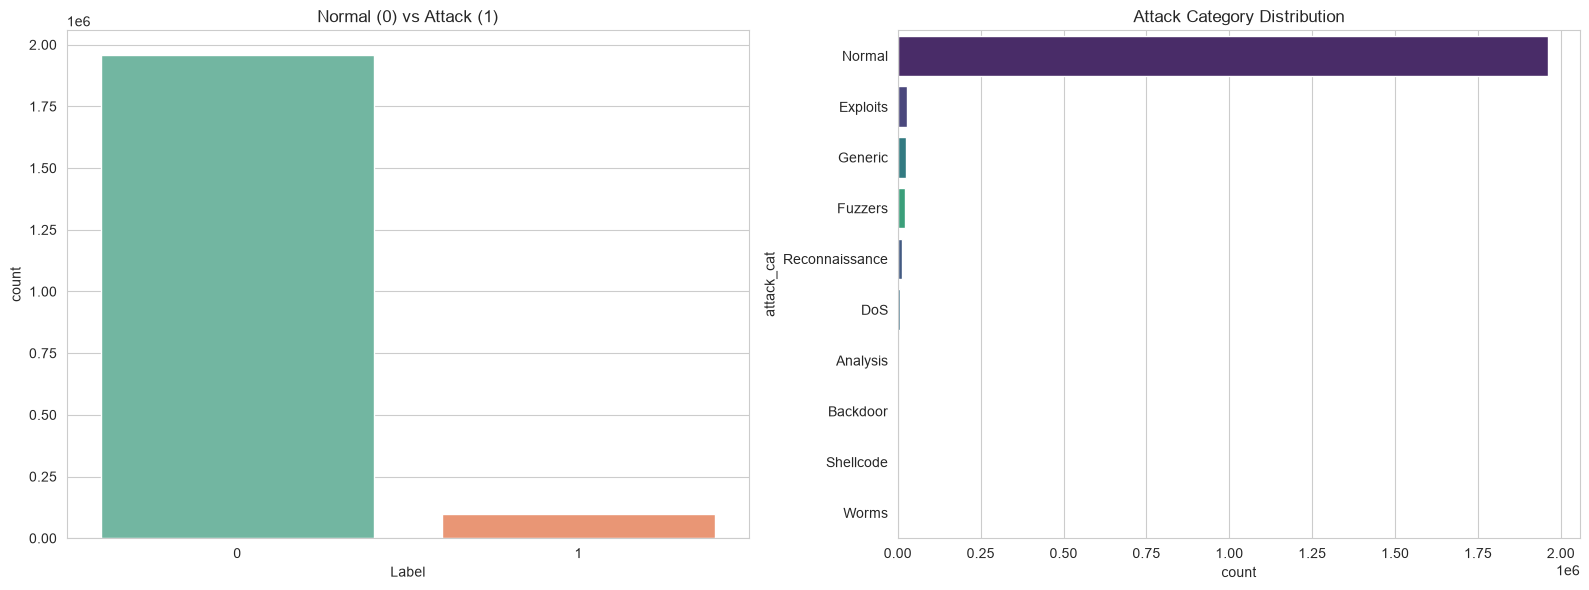

In [14]:
if "Label" in df.columns and "attack_cat" in df.columns:
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    sns.countplot(x="Label", data=df, hue="Label", legend=False, ax=axes[0], palette="Set2")
    axes[0].set_title("Normal (0) vs Attack (1)")
    order = df["attack_cat"].value_counts().index
    sns.countplot(y="attack_cat", data=df, hue="attack_cat", legend=False,
                  order=order, ax=axes[1], palette="viridis")
    axes[1].set_title("Attack Category Distribution")
    plt.tight_layout()
    plt.show()

In [15]:
cat_cols = [c for c in ["proto", "state", "service"] if c in df.columns]
for c in cat_cols:
    print(f"=== {c.upper()} VALUE COUNTS (top 15) ===")
    print(df[c].value_counts().head(15))
    print()

=== PROTO VALUE COUNTS (top 15) ===
proto
tcp       1448859
udp        588026
arp          6658
unas         4765
ospf         3964
icmp          498
sctp          444
any           138
gre            95
rsvp           92
ipv6           85
sep            81
sun-nd         81
swipe          81
mobile         81
Name: count, dtype: int64

=== STATE VALUE COUNTS (top 15) ===
state
FIN    1433508
CON     543297
INT      75336
REQ       6050
RST        525
ECO        313
CLO        160
URH        108
ACC         41
PAR         30
URN          8
no           8
MAS          8
TST          8
ECR          8
Name: count, dtype: int64

=== SERVICE VALUE COUNTS (top 15) ===
service
-           1169178
dns          386755
http         203531
ftp-data     124849
smtp          81132
ssh           46981
ftp           45074
pop3           1490
ssl             142
snmp            113
dhcp            102
radius           37
irc              31
Name: count, dtype: int64



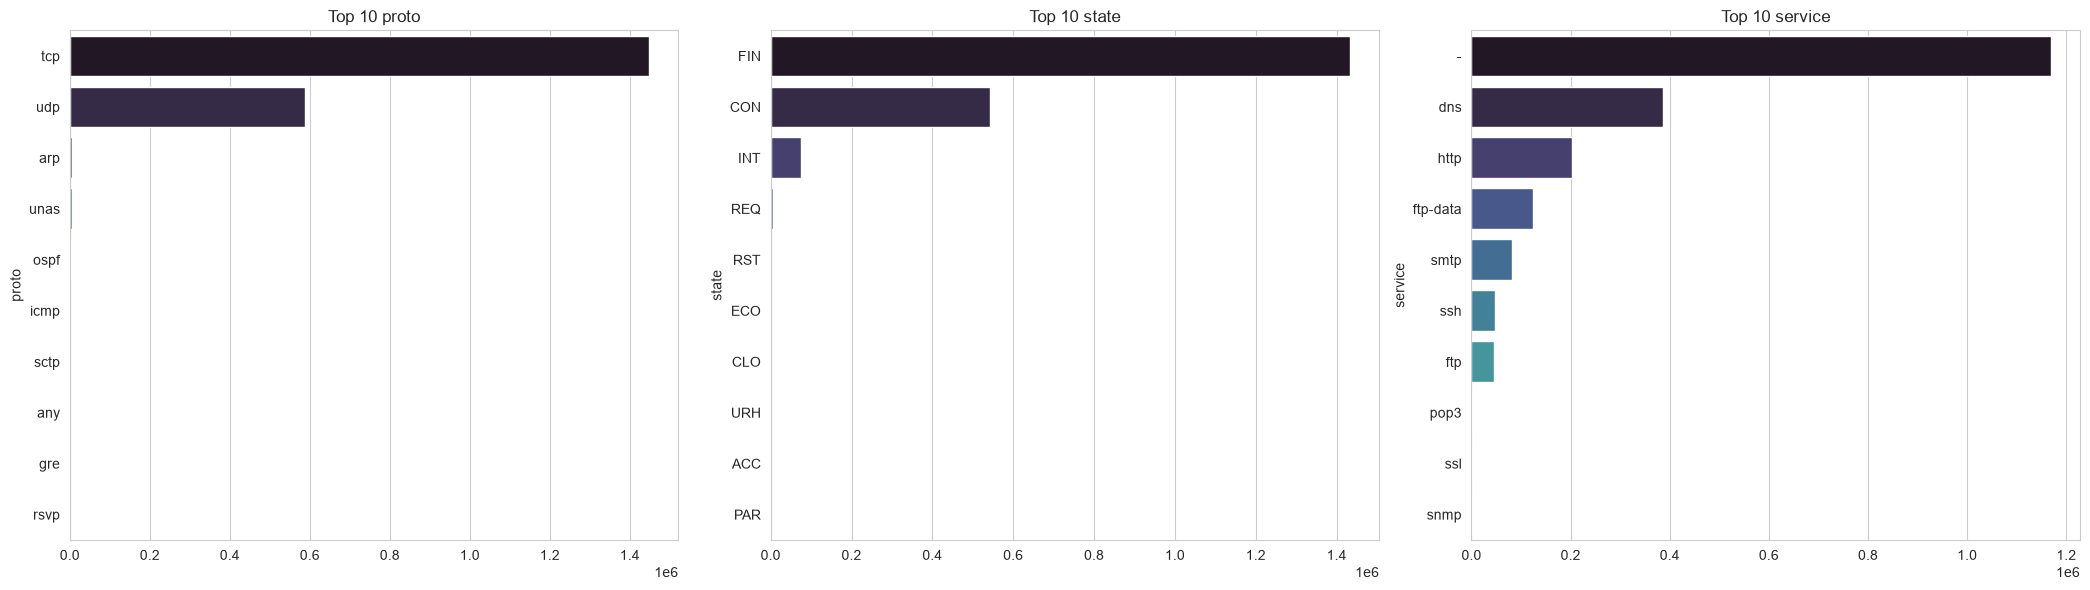

In [16]:
if cat_cols:
    fig, axes = plt.subplots(1, len(cat_cols), figsize=(7 * len(cat_cols), 6))
    axes = np.atleast_1d(axes)
    for ax, c in zip(axes, cat_cols):
        top = df[c].value_counts().head(10)
        sns.barplot(x=top.values, y=top.index, hue=top.index, legend=False, ax=ax, palette="mako")
        ax.set_title(f"Top 10 {c}")
    plt.tight_layout()
    plt.show()

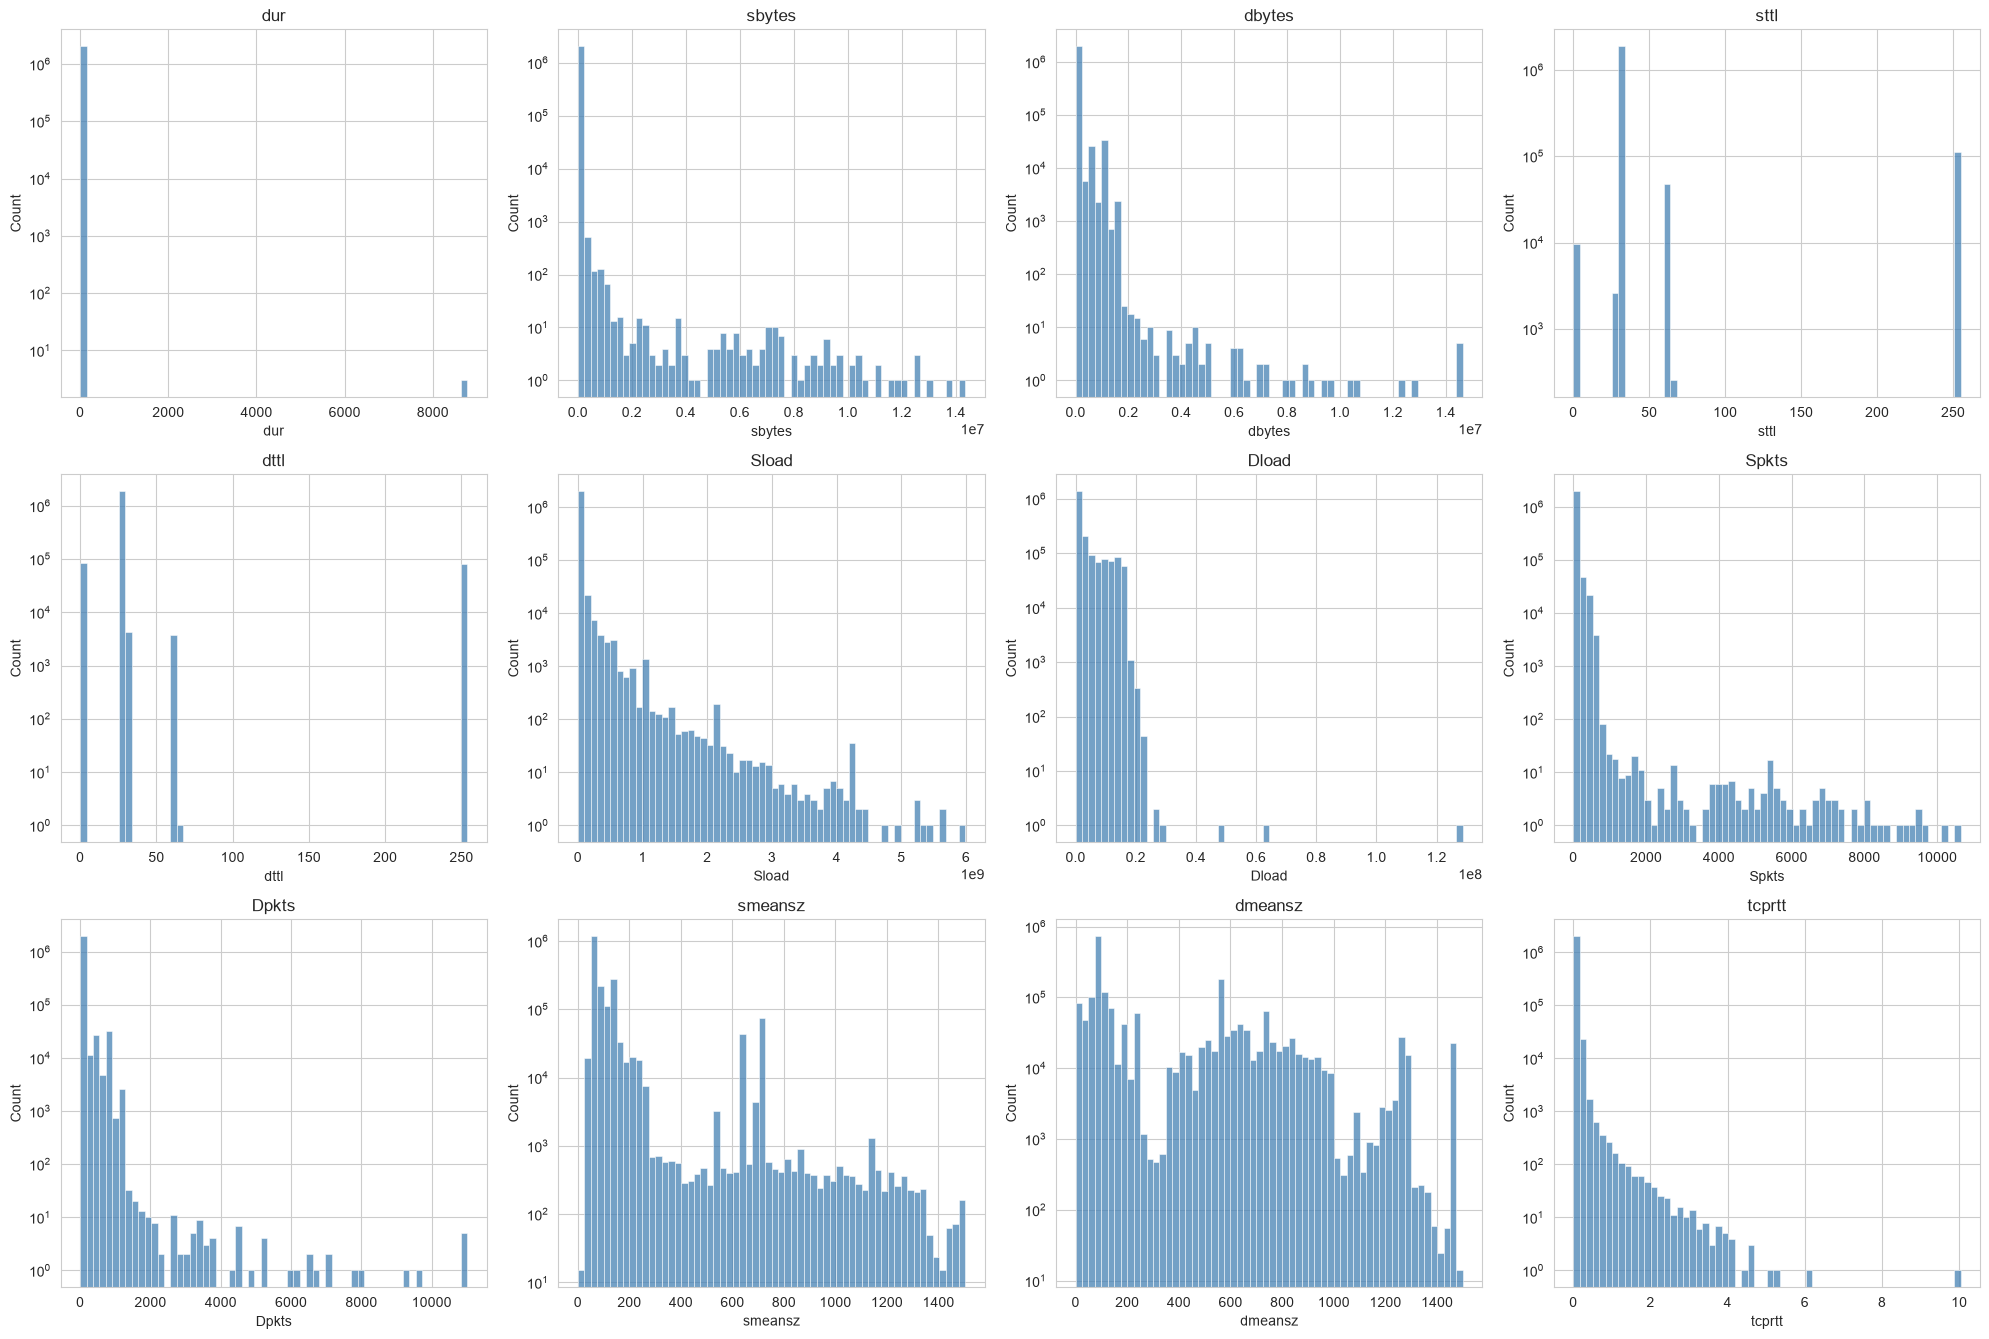

In [17]:
num_cols = ["dur", "sbytes", "dbytes", "sttl", "dttl", "Sload", "Dload",
            "Spkts", "Dpkts", "smeansz", "dmeansz", "tcprtt"]
num_cols = [c for c in num_cols if c in df.columns]

if num_cols:
    ncols = 4
    nrows = int(np.ceil(len(num_cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(20, 4.5 * nrows))
    axes = np.atleast_1d(axes).flatten()
    for i, c in enumerate(num_cols):
        sns.histplot(df[c], bins=60, ax=axes[i], color="steelblue")
        axes[i].set_yscale("log")
        axes[i].set_title(c)
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])
    plt.tight_layout()
    plt.show()

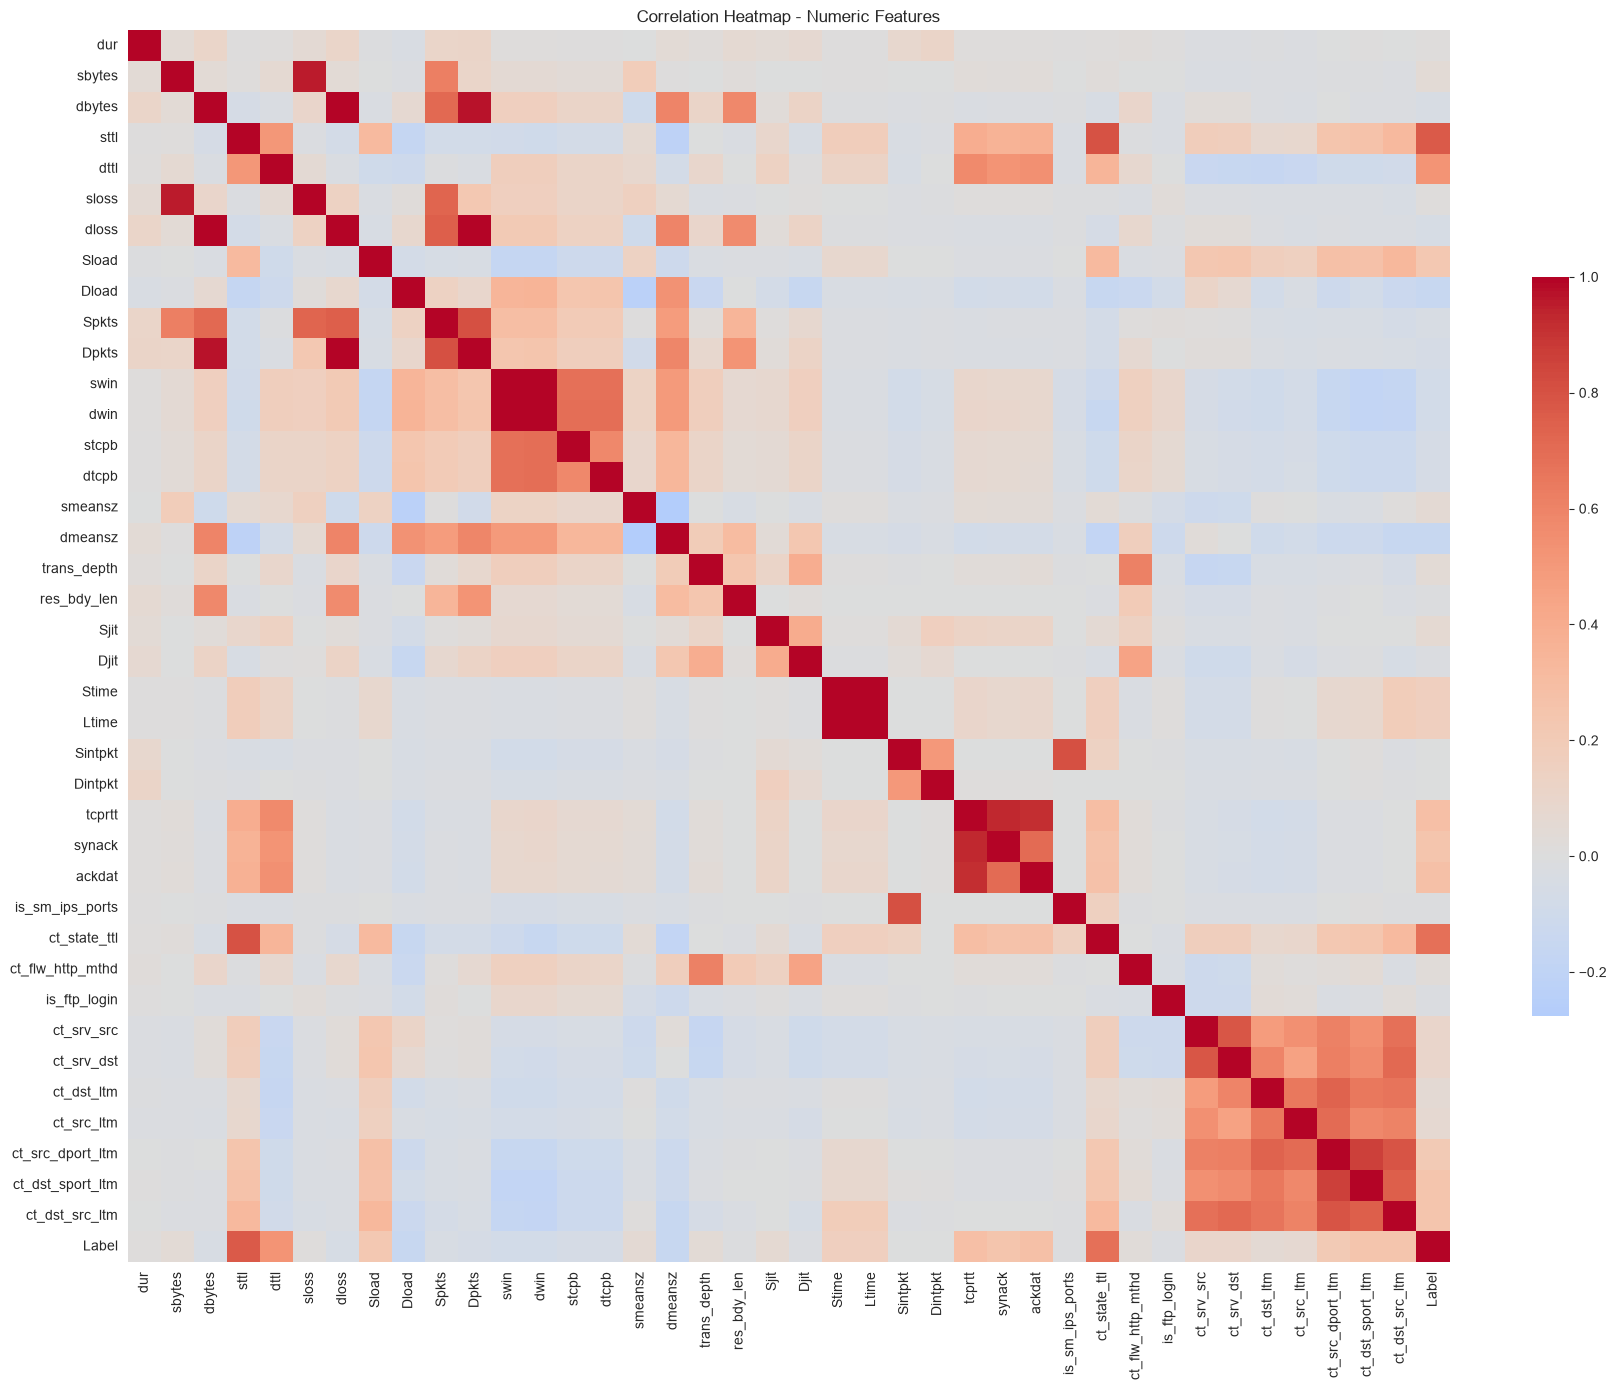

In [18]:
numeric_df = df.select_dtypes(include=[np.number])
corr = numeric_df.corr()

fig, ax = plt.subplots(figsize=(18, 14))
sns.heatmap(corr, cmap="coolwarm", center=0, ax=ax, cbar_kws={"shrink": 0.6})
ax.set_title("Correlation Heatmap - Numeric Features")
plt.tight_layout()
plt.show()

In [19]:
if "Label" in corr.columns:
    print("=== TOP FEATURES CORRELATED WITH Label ===")
    target_corr = corr["Label"].drop("Label").sort_values(key=abs, ascending=False)
    print(target_corr.head(15))

=== TOP FEATURES CORRELATED WITH Label ===
sttl                0.765934
ct_state_ttl        0.684891
dttl                0.522134
tcprtt              0.283253
ackdat              0.278482
synack              0.246370
ct_dst_sport_ltm    0.245806
ct_dst_src_ltm      0.243383
Sload               0.225527
ct_src_dport_ltm    0.211701
Ltime               0.158901
Stime               0.158901
Dload              -0.146891
dmeansz            -0.146492
ct_srv_src          0.102415
Name: Label, dtype: float64


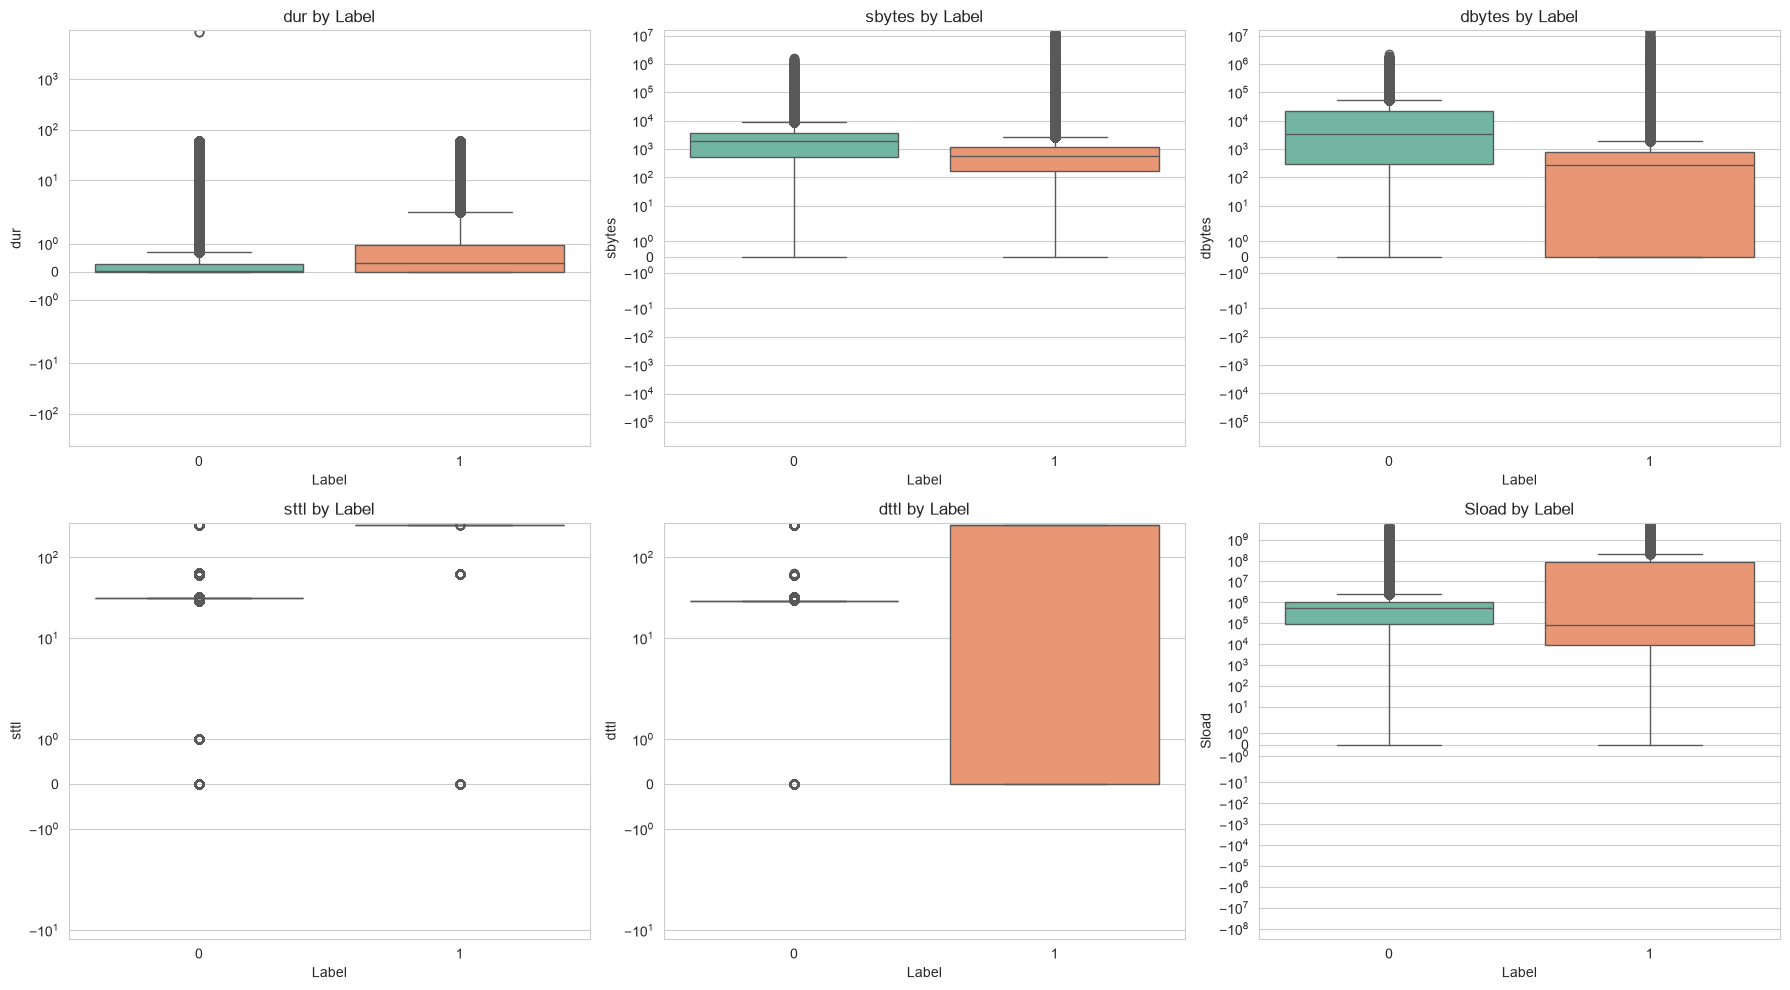

In [20]:
if "Label" in df.columns:
    box_feats = [c for c in ["dur", "sbytes", "dbytes", "sttl", "dttl", "Sload"] if c in df.columns]
    if box_feats:
        fig, axes = plt.subplots(2, 3, figsize=(18, 10))
        axes = axes.flatten()
        for i, c in enumerate(box_feats):
            sns.boxplot(x="Label", y=c, data=df, hue="Label", legend=False, ax=axes[i], palette="Set2")
            axes[i].set_yscale("symlog")
            axes[i].set_title(f"{c} by Label")
        for j in range(i + 1, len(axes)):
            fig.delaxes(axes[j])
        plt.tight_layout()
        plt.show()

In [21]:
print("=" * 60)
print("SUMMARY")
print("=" * 60)
print("Combined shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("Columns with missing values:", list(missing.index) if not missing.empty else "None")
if "Label" in df.columns:
    print("\nLabel distribution:\n", df["Label"].value_counts())
if "attack_cat" in df.columns:
    print("\nAttack category distribution:\n", df["attack_cat"].value_counts())

SUMMARY
Combined shape: (2059415, 49)
Duplicate rows: 0
Columns with missing values: ['attack_cat', 'is_ftp_login', 'ct_flw_http_mthd']

Label distribution:
 Label
0    1959772
1      99643
Name: count, dtype: int64

Attack category distribution:
 attack_cat
Normal            1959772
Exploits            27599
Generic             25378
Fuzzers             21795
Reconnaissance      13357
DoS                  5665
Analysis             2184
Backdoor             1983
Shellcode            1511
Worms                 171
Name: count, dtype: int64


In [22]:
df_fe = df.copy()

drop_cols = [c for c in ["srcip", "dstip", "Stime", "Ltime"] if c in df_fe.columns]
df_fe = df_fe.drop(columns=drop_cols)
print("Dropped columns:", drop_cols)
print("Shape after dropping identifiers:", df_fe.shape)

Dropped columns: ['srcip', 'dstip', 'Stime', 'Ltime']
Shape after dropping identifiers: (2059415, 45)


In [23]:
cat_cols = [c for c in ["proto", "state", "service"] if c in df_fe.columns]
print("Unique value counts before encoding:")
for c in cat_cols:
    print(f"  {c}: {df_fe[c].nunique()} unique values")

df_fe = pd.get_dummies(df_fe, columns=cat_cols, prefix=cat_cols)
print("\nShape after one-hot encoding:", df_fe.shape)

Unique value counts before encoding:
  proto: 135 unique values
  state: 16 unique values
  service: 13 unique values

Shape after one-hot encoding: (2059415, 206)


In [24]:
if "attack_cat" in df_fe.columns:
    from sklearn.preprocessing import LabelEncoder
    le = LabelEncoder()
    df_fe["attack_cat_encoded"] = le.fit_transform(df_fe["attack_cat"])
    print("Attack category mapping:")
    for i, cls in enumerate(le.classes_):
        print(f"  {cls} -> {i}")

Attack category mapping:
  Analysis -> 0
  Backdoor -> 1
  DoS -> 2
  Exploits -> 3
  Fuzzers -> 4
  Generic -> 5
  Normal -> 6
  Reconnaissance -> 7
  Shellcode -> 8
  Worms -> 9


In [25]:
if "sbytes" in df_fe.columns and "dbytes" in df_fe.columns:
    df_fe["bytes_ratio"] = df_fe["sbytes"] / (df_fe["dbytes"] + 1)  # +1 avoids divide-by-zero

if "Spkts" in df_fe.columns and "Dpkts" in df_fe.columns:
    df_fe["pkts_ratio"] = df_fe["Spkts"] / (df_fe["Dpkts"] + 1)

new_feats = [c for c in ["bytes_ratio", "pkts_ratio"] if c in df_fe.columns]
print("New derived features:", new_feats)
print(df_fe[new_feats].describe())

New derived features: ['bytes_ratio', 'pkts_ratio']
        bytes_ratio    pkts_ratio
count  2.059415e+06  2.059415e+06
mean   1.861096e+01  9.741235e-01
std    3.295273e+02  2.204369e+00
min    0.000000e+00  0.000000e+00
25%    1.118056e-01  6.666667e-01
50%    7.975460e-01  9.032258e-01
75%    1.378773e+00  9.600000e-01
max    5.494400e+04  5.120000e+02


In [26]:
print("Final engineered dataset shape:", df_fe.shape)
print("\nSample of engineered features:")
print(df_fe.head())

print("\nColumn count comparison:")
print(f"  Original (post-EDA) columns: {df.shape[1]}")
print(f"  Engineered dataset columns:  {df_fe.shape[1]}")

Final engineered dataset shape: (2059415, 209)

Sample of engineered features:
   sport dsport       dur  sbytes  dbytes  sttl  dttl  sloss  dloss  \
0   1390     53  0.001055     132     164    31    29      0      0   
1  33661   1024  0.036133     528     304    31    29      0      0   
2   1464     53  0.001119     146     178    31    29      0      0   
3   3593     53  0.001209     132     164    31    29      0      0   
4  49664     53  0.001169     146     178    31    29      0      0   

          Sload  ...  service_irc  service_pop3  service_radius  service_smtp  \
0  500473.93750  ...        False         False           False         False   
1   87676.08594  ...        False         False           False         False   
2  521894.53130  ...        False         False           False         False   
3  436724.56250  ...        False         False           False         False   
4  499572.25000  ...        False         False           False         False   

   serv

**Feature Selection Process**

In [27]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd

def parse_port(val):
    """Handles both decimal ('53') and hex ('0x000b') port strings."""
    try:
        return int(str(val), 0)
    except (ValueError, TypeError):
        return np.nan

def clean_features(df_source, target_col):
    """Rebuilds X, y from df_fe, fixing known dtype issues."""
    drop_for_X = [c for c in ["Label", "attack_cat", "attack_cat_encoded"] if c in df_source.columns]
    X = df_source.drop(columns=drop_for_X).copy()
    y = df_source[target_col].copy()

    # Fix sport/dsport hex-formatted strings
    for col in ["sport", "dsport"]:
        if col in X.columns:
            X[col] = X[col].apply(parse_port)
            X[col] = X[col].fillna(X[col].median())

    # Fix ct_ftp_cmd mixed-type column
    if "ct_ftp_cmd" in X.columns:
        X["ct_ftp_cmd"] = pd.to_numeric(X["ct_ftp_cmd"].astype(str).str.strip(), errors="coerce").fillna(0)

    # Safety net: coerce any remaining non-numeric columns
    non_numeric = X.select_dtypes(include=["object", "string"]).columns.tolist()
    for col in non_numeric:
        X[col] = pd.to_numeric(X[col].astype(str).str.strip(), errors="coerce").fillna(0)

    return X, y

print("Setup complete.")

Setup complete.


In [28]:
def run_feature_selection(X, y, target_name, k=30, corr_threshold=0.9, min_onehot_freq=0.001):
    print("=" * 60)
    print(f"FEATURE SELECTION FOR TARGET: {target_name}")
    print("=" * 60)
    print("Starting shape:", X.shape)

    # --- Step 1: Drop constant columns ---
    constant_cols = X.columns[X.nunique() <= 1].tolist()
    print(f"\n[1] Dropping {len(constant_cols)} constant columns: {constant_cols}")
    X = X.drop(columns=constant_cols)

    # --- Step 2: Sparsity pruning on one-hot columns ---
    onehot_cols = X.select_dtypes(include=["bool"]).columns.tolist()
    sparse_onehot = [c for c in onehot_cols if X[c].mean() < min_onehot_freq]
    print(f"[2] Dropping {len(sparse_onehot)} ultra-sparse one-hot columns (out of {len(onehot_cols)})")
    X = X.drop(columns=sparse_onehot)
    print(f"    Shape after pruning: {X.shape}")

    # --- Step 3: MI on stratified sample (used for both tie-breaking and ranking) ---
    X_sample, _, y_sample, _ = train_test_split(
        X, y, train_size=0.1, stratify=y, random_state=42
    )
    print(f"\n[3] MI computed on stratified sample: {X_sample.shape[0]} rows")

    mi_scores = mutual_info_classif(X_sample, y_sample, random_state=42, n_jobs=-1)
    mi_series = pd.Series(mi_scores, index=X_sample.columns)

    # --- Step 4: Correlation filter, using MI to break ties ---
    corr_matrix = X.corr().abs()
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

    to_drop_corr = set()
    for col in upper.columns:
        correlated_with = upper.index[upper[col] > corr_threshold].tolist()
        for other in correlated_with:
            if mi_series.get(col, 0) >= mi_series.get(other, 0):
                to_drop_corr.add(other)
            else:
                to_drop_corr.add(col)

    to_drop_corr = list(to_drop_corr)
    print(f"\n[4] Correlation Filter (threshold={corr_threshold}): dropping {len(to_drop_corr)} redundant features")
    print(f"    Dropped: {to_drop_corr}")
    X = X.drop(columns=to_drop_corr)
    mi_ranked = mi_series.drop(labels=to_drop_corr, errors="ignore").sort_values(ascending=False)
    print(f"    Shape after correlation filter: {X.shape}")

    # --- Step 5: Select top-K by MI ---
    top_features = mi_ranked.head(k).index.tolist()
    X_selected = X[top_features]

    print(f"\n[5] Top {k} features by Mutual Information:")
    print(mi_ranked.head(k))
    print(f"\nFinal X_selected shape: {X_selected.shape}")

    return X_selected, mi_ranked, top_features

print("Pipeline function defined.")

Pipeline function defined.


In [29]:
X_raw_binary, y_binary = clean_features(df_fe, "Label")
X_selected_binary, mi_ranked_binary, top_features_binary = run_feature_selection(
    X_raw_binary, y_binary, target_name="Label (Binary)", k=30
)

FEATURE SELECTION FOR TARGET: Label (Binary)
Starting shape: (2059415, 206)

[1] Dropping 0 constant columns: []
[2] Dropping 148 ultra-sparse one-hot columns (out of 164)
    Shape after pruning: (2059415, 58)

[3] MI computed on stratified sample: 205941 rows

[4] Correlation Filter (threshold=0.9): dropping 12 redundant features
    Dropped: ['state_CON', 'sloss', 'swin', 'dloss', 'service_ftp', 'proto_udp', 'state_FIN', 'proto_tcp', 'ackdat', 'synack', 'is_ftp_login', 'Dpkts']
    Shape after correlation filter: (2059415, 46)

[5] Top 30 features by Mutual Information:
sttl                0.182640
dttl                0.168210
ct_state_ttl        0.155601
sbytes              0.148653
bytes_ratio         0.145525
dbytes              0.125930
pkts_ratio          0.114030
dmeansz             0.110809
Sload               0.102582
Dintpkt             0.099550
Dload               0.098790
smeansz             0.096483
tcprtt              0.091537
dur                 0.086391
Sintpkt       

In [30]:
X_raw_multiclass, y_multiclass = clean_features(df_fe, "attack_cat_encoded")
X_selected_multiclass, mi_ranked_multiclass, top_features_multiclass = run_feature_selection(
    X_raw_multiclass, y_multiclass, target_name="attack_cat_encoded (Multiclass)", k=30
)

FEATURE SELECTION FOR TARGET: attack_cat_encoded (Multiclass)
Starting shape: (2059415, 206)

[1] Dropping 0 constant columns: []
[2] Dropping 148 ultra-sparse one-hot columns (out of 164)
    Shape after pruning: (2059415, 58)

[3] MI computed on stratified sample: 205941 rows

[4] Correlation Filter (threshold=0.9): dropping 12 redundant features
    Dropped: ['state_CON', 'sloss', 'swin', 'dloss', 'service_ftp', 'ct_ftp_cmd', 'proto_udp', 'state_FIN', 'proto_tcp', 'ackdat', 'synack', 'Dpkts']
    Shape after correlation filter: (2059415, 46)

[5] Top 30 features by Mutual Information:
sttl                0.190853
bytes_ratio         0.186055
sbytes              0.184717
dttl                0.178177
ct_state_ttl        0.165785
dbytes              0.147264
Sload               0.131853
pkts_ratio          0.130896
dmeansz             0.130188
smeansz             0.129885
Dload               0.115830
Dintpkt             0.112487
dsport              0.103916
tcprtt              0.102465

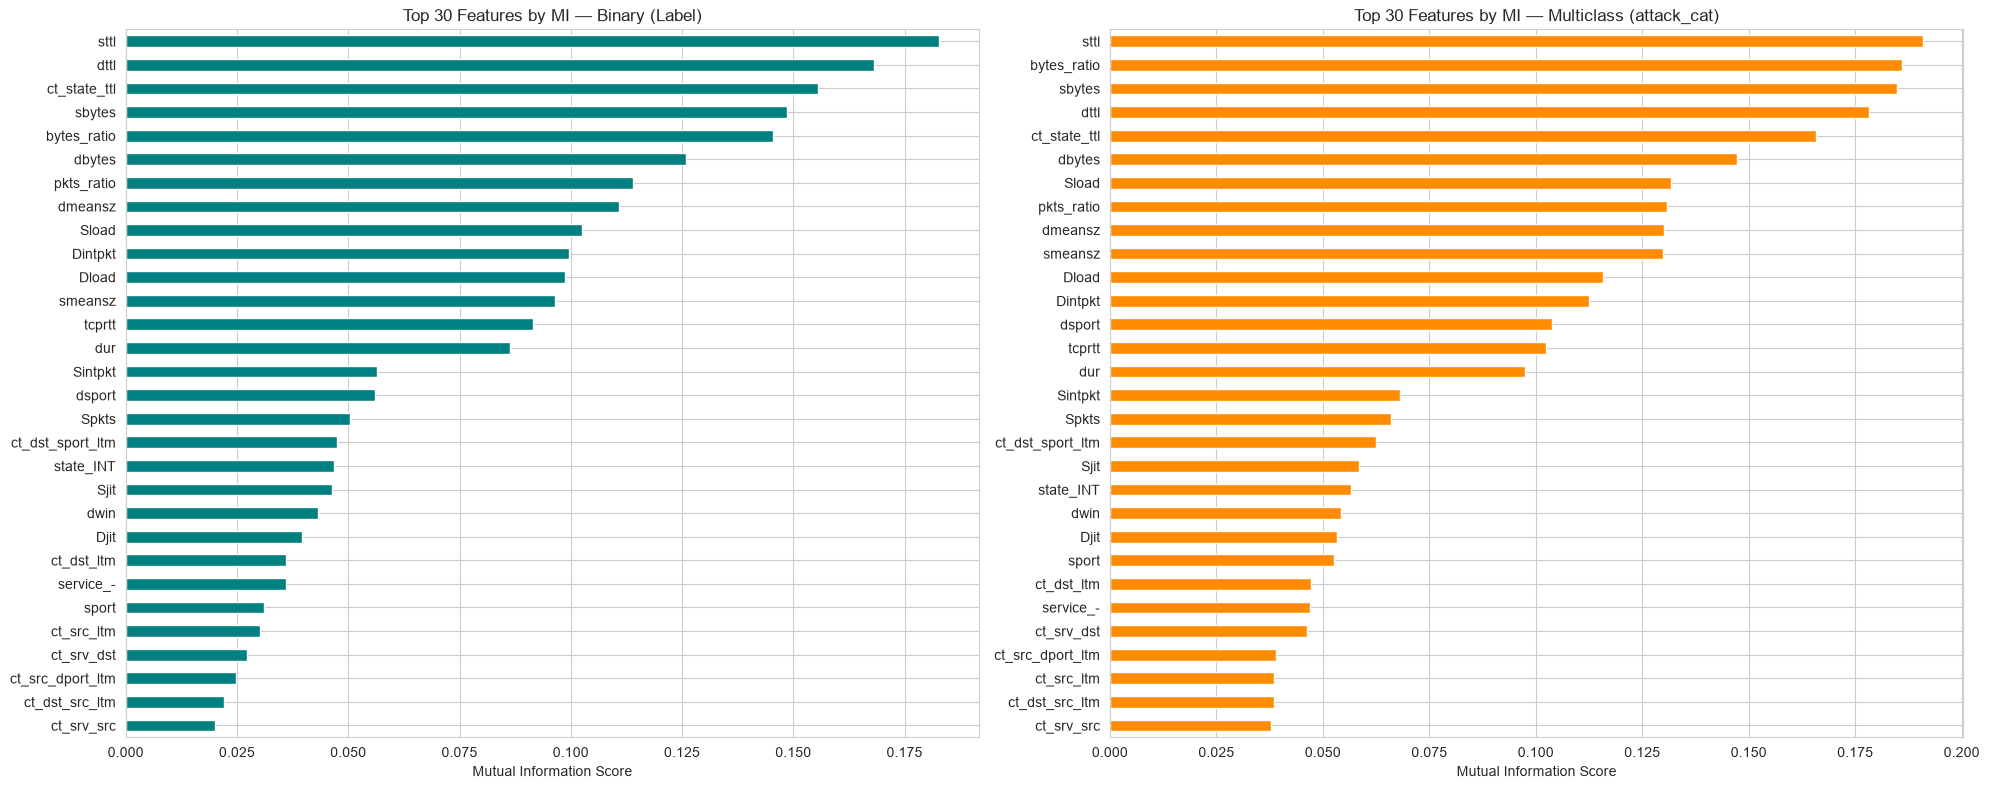

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

mi_ranked_binary.head(30).sort_values().plot(kind="barh", color="teal", ax=axes[0])
axes[0].set_title("Top 30 Features by MI — Binary (Label)")
axes[0].set_xlabel("Mutual Information Score")

mi_ranked_multiclass.head(30).sort_values().plot(kind="barh", color="darkorange", ax=axes[1])
axes[1].set_title("Top 30 Features by MI — Multiclass (attack_cat)")
axes[1].set_xlabel("Mutual Information Score")

plt.tight_layout()
plt.show()

In [32]:
print("=" * 60)
print("FEATURE SELECTION SUMMARY — BOTH TARGETS")
print("=" * 60)
print(f"Binary (Label):              X_selected_binary shape = {X_selected_binary.shape}")
print(f"Multiclass (attack_cat):     X_selected_multiclass shape = {X_selected_multiclass.shape}")
print(f"\nOverlap between the two top-30 sets:")
overlap = set(top_features_binary) & set(top_features_multiclass)
print(f"  {len(overlap)} features in common: {sorted(overlap)}")
print(f"  {len(set(top_features_binary) - overlap)} unique to binary")
print(f"  {len(set(top_features_multiclass) - overlap)} unique to multiclass")

FEATURE SELECTION SUMMARY — BOTH TARGETS
Binary (Label):              X_selected_binary shape = (2059415, 30)
Multiclass (attack_cat):     X_selected_multiclass shape = (2059415, 30)

Overlap between the two top-30 sets:
  30 features in common: ['Dintpkt', 'Djit', 'Dload', 'Sintpkt', 'Sjit', 'Sload', 'Spkts', 'bytes_ratio', 'ct_dst_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'ct_src_dport_ltm', 'ct_src_ltm', 'ct_srv_dst', 'ct_srv_src', 'ct_state_ttl', 'dbytes', 'dmeansz', 'dsport', 'dttl', 'dur', 'dwin', 'pkts_ratio', 'sbytes', 'service_-', 'smeansz', 'sport', 'state_INT', 'sttl', 'tcprtt']
  0 unique to binary
  0 unique to multiclass


In [33]:
# ================= CELL 1: setup, constants, environment =================
import os, sys, gc, json, time, pickle, platform
import numpy as np, pandas as pd
import sklearn, xgboost, imblearn
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.feature_selection import mutual_info_classif, SelectKBest, f_classif
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

SEED, K = 42, 30
CORR_THRESHOLD, MIN_ONEHOT_FREQ = 0.9, 0.001
MI_FRAC, TEST_SIZE = 0.10, 0.20
SAMPLING_STRATEGY = {9: 1000, 8: 3000, 1: 3000, 0: 3000, 2: 5000}
XGB_PARAMS = dict(objective="multi:softprob", num_class=10, eval_metric="mlogloss",
                  n_estimators=300, max_depth=5, learning_rate=0.1, reg_lambda=2.0,
                  random_state=SEED, n_jobs=-1, tree_method="hist")
GWO_WOLVES, GWO_ITERS = 8, 8
CKPT = "leakfree_checkpoint.pkl"
CLASS_NAMES = ["Analysis","Backdoor","DoS","Exploits","Fuzzers","Generic",
               "Normal","Reconnaissance","Shellcode","Worms"]

# Reference values from the CURRENT paper (selection fitted on the FULL data = leaky), XGBoost only
OLD = {"Hybrid": {"acc": 0.9845, "f1": 0.6629},
       "ANOVA":  {"acc": 0.9829, "f1": 0.5988},
       "GWO":    {"acc": 0.9830, "f1": 0.5740}}
OLD_FEATURES = ["sttl","bytes_ratio","sbytes","dttl","ct_state_ttl","dbytes","Sload","pkts_ratio",
    "dmeansz","smeansz","Dload","Dintpkt","dsport","tcprtt","dur","Sintpkt","Spkts","ct_dst_sport_ltm",
    "Sjit","state_INT","dwin","Djit","sport","ct_dst_ltm","service_-","ct_srv_dst","ct_src_dport_ltm",
    "ct_src_ltm","ct_dst_src_ltm","ct_srv_src"]

# ---- reproducibility info (paste this output back to me) ----
print("Python   :", sys.version.split()[0], "|", platform.platform())
print("CPU cores:", os.cpu_count())
try:
    import psutil; print("RAM (GB) :", round(psutil.virtual_memory().total/1e9, 1))
except Exception:
    print("RAM (GB) : psutil not available")
for m in (np, pd, sklearn, xgboost, imblearn):
    print(f"{m.__name__:10s}:", m.__version__)
print("df_fe in memory:", "df_fe" in globals(), "| shape:", df_fe.shape if "df_fe" in globals() else None)

lf_results, selections = {}, {}
def save_ckpt():
    with open(CKPT, "wb") as f:
        pickle.dump({"results": lf_results, "selections": selections}, f)

Python   : 3.11.0 | Windows-10-10.0.26300-SP0
CPU cores: 16
RAM (GB) : 16.4
numpy     : 2.4.6
pandas    : 3.0.3
sklearn   : 1.9.0
xgboost   : 3.2.0
imblearn  : 0.14.2
df_fe in memory: True | shape: (2059415, 209)


In [34]:
# ======= CELL 2: build features, SPLIT FIRST, impute with TRAIN statistics =======
def parse_port(val):
    try:
        return int(str(val), 0)
    except (ValueError, TypeError):
        return np.nan

TARGET = "attack_cat_encoded"
drop_for_X = [c for c in ["Label", "attack_cat", "attack_cat_encoded"] if c in df_fe.columns]
X_all = df_fe.drop(columns=drop_for_X).copy()     # the binary Label is NOT an input
y_all = df_fe[TARGET].copy()

for col in ["sport", "dsport"]:
    X_all[col] = X_all[col].apply(parse_port)     # unparseable -> NaN (imputed AFTER the split)
if "ct_ftp_cmd" in X_all.columns:
    X_all["ct_ftp_cmd"] = pd.to_numeric(X_all["ct_ftp_cmd"].astype(str).str.strip(), errors="coerce").fillna(0)
for col in X_all.select_dtypes(include=["object", "string"]).columns.tolist():
    X_all[col] = pd.to_numeric(X_all[col].astype(str).str.strip(), errors="coerce").fillna(0)
print("NaN ports before imputation:", int(X_all[["sport", "dsport"]].isna().sum().sum()))

# Same split as before. The partition depends only on (n, y, test_size, random_state),
# so the test rows are identical to the old experiment.
X_tr, X_te, y_tr, y_te = train_test_split(X_all, y_all, test_size=TEST_SIZE,
                                          stratify=y_all, random_state=SEED)
del X_all; gc.collect()

port_median = X_tr[["sport", "dsport"]].median()  # TRAIN median only
for col in ["sport", "dsport"]:
    X_tr[col] = X_tr[col].fillna(port_median[col])
    X_te[col] = X_te[col].fillna(port_median[col])

print("X_tr:", X_tr.shape, "| X_te:", X_te.shape, "| NaN left:", int(X_tr.isna().sum().sum() + X_te.isna().sum().sum()))
if "X_test" in globals():
    print("test rows identical to the old split:", X_te.index.equals(X_test.index))
print("train class counts:", y_tr.value_counts().sort_index().to_dict())

NaN ports before imputation: 9
X_tr: (1647532, 206) | X_te: (411883, 206) | NaN left: 0
train class counts: {0: 1747, 1: 1586, 2: 4532, 3: 22079, 4: 17436, 5: 20302, 6: 1567818, 7: 10686, 8: 1209, 9: 137}


In [35]:
# ============= CELL 3: selectors, every one FITTED ON TRAIN ROWS ONLY =============
def fit_stage1(X):
    """Stage 1 (constant + ultra-sparse one-hot pruning) learned from the given rows."""
    const_cols = X.columns[X.nunique() <= 1].tolist()
    Xp = X.drop(columns=const_cols)
    onehot = Xp.select_dtypes(include=["bool"]).columns.tolist()
    sparse_cols = [c for c in onehot if Xp[c].mean() < MIN_ONEHOT_FREQ]
    base_cols = [c for c in Xp.columns if c not in sparse_cols]
    return base_cols, const_cols, sparse_cols

def fit_hybrid(X, y, k=K):
    t0 = time.time()
    base_cols, const_cols, sparse_cols = fit_stage1(X)
    Xb = X[base_cols]
    # MI on a stratified 10% sample of the TRAINING rows
    Xs, _, ys, _ = train_test_split(Xb, y, train_size=MI_FRAC, stratify=y, random_state=SEED)
    mi = pd.Series(mutual_info_classif(Xs, ys, random_state=SEED, n_jobs=-1), index=Xs.columns)
    # correlation filter on the TRAINING rows, MI breaks ties (same logic as before)
    corr = Xb.corr().abs()
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    drop = set()
    for col in upper.columns:
        for other in upper.index[upper[col] > CORR_THRESHOLD].tolist():
            if mi.get(col, 0) >= mi.get(other, 0): drop.add(other)
            else: drop.add(col)
    mi_ranked = mi.drop(labels=list(drop), errors="ignore").sort_values(ascending=False)
    selected = mi_ranked.head(k).index.tolist()
    info = dict(n_start=X.shape[1], n_const=len(const_cols), n_sparse=len(sparse_cols),
                n_after_stage1=len(base_cols), n_corr_dropped=len(drop),
                n_after_stage2=len(base_cols) - len(drop), corr_dropped=sorted(drop))
    return selected, mi_ranked, info, base_cols, time.time() - t0

def fit_anova(X, y, base_cols, k=K):
    t0 = time.time()
    sel = SelectKBest(f_classif, k=k).fit(X[base_cols], y)
    return [c for c, keep in zip(base_cols, sel.get_support()) if keep], time.time() - t0

def fit_gwo(X, y, base_cols, k=K, n_wolves=GWO_WOLVES, n_iter=GWO_ITERS):
    # SAME simplified GWO as the earlier experiment (kept identical on purpose, so that
    # only the leakage changes). Its canonical-GWO corrections are planned for Item 6.
    t0 = time.time()
    Xs, _, ys, _ = train_test_split(X[base_cols], y, train_size=MI_FRAC, stratify=y, random_state=SEED)
    n_features = Xs.shape[1]
    rng = np.random.default_rng(SEED)
    positions = rng.random((n_wolves, n_features))
    def fitness(mask):
        idx = np.where(mask > 0.5)[0]
        if len(idx) == 0: return 1.0
        clf = DecisionTreeClassifier(max_depth=8, random_state=SEED)
        return 1 - cross_val_score(clf, Xs.iloc[:, idx], ys, cv=3, n_jobs=-1).mean()
    fit_vals = np.array([fitness(positions[i]) for i in range(n_wolves)])
    for it in range(n_iter):
        order = np.argsort(fit_vals)
        alpha, beta, delta = positions[order[0]], positions[order[1]], positions[order[2]]
        a = 2 - it * (2 / n_iter)
        for i in range(n_wolves):
            for lead in (alpha, beta, delta):
                r1, r2 = rng.random(n_features), rng.random(n_features)
                A, C = 2 * a * r1 - a, 2 * r2
                positions[i] = positions[i] - A * np.abs(C * lead - positions[i])
            positions[i] = np.clip(positions[i], 0, 1)
            fit_vals[i] = fitness(positions[i])
    best = positions[np.argmin(fit_vals)]
    return Xs.columns[np.argsort(-best)[:k]].tolist(), time.time() - t0

def evaluate_selection(name, cols, sel_time):
    smote = SMOTE(random_state=SEED, k_neighbors=5, sampling_strategy=SAMPLING_STRATEGY)
    Xr, yr = smote.fit_resample(X_tr[cols], y_tr)       # SMOTE on TRAIN rows only
    t0 = time.time()
    model = XGBClassifier(**XGB_PARAMS).fit(Xr, yr)
    train_time = time.time() - t0
    pred = model.predict(X_te[cols])
    return dict(method=name, n_features=len(cols), sel_time=sel_time, train_time=train_time,
                accuracy=accuracy_score(y_te, pred),
                precision_macro=precision_score(y_te, pred, average="macro", zero_division=0),
                recall_macro=recall_score(y_te, pred, average="macro", zero_division=0),
                f1_macro=f1_score(y_te, pred, average="macro", zero_division=0),
                f1_per_class=f1_score(y_te, pred, average=None, labels=list(range(10)), zero_division=0).tolist())

In [36]:
# ======================= CELL 4: Hybrid (train-only) =======================
sel_h, mi_ranked, info, base_cols, t_h = fit_hybrid(X_tr, y_tr)
selections["Hybrid"] = {"cols": sel_h, "time": t_h, "info": info, "base_cols": base_cols}
print(f"Hybrid selection time: {t_h:.1f}s")
print({k: v for k, v in info.items() if k != "corr_dropped"})
print("Correlation-dropped:", info["corr_dropped"])
print(mi_ranked.head(K).round(4).to_string())
lf_results["Hybrid"] = evaluate_selection("Hybrid (train-only)", sel_h, t_h)
r = lf_results["Hybrid"]
print(f"Hybrid | acc {r['accuracy']:.4f} | macro-F1 {r['f1_macro']:.4f} | XGB fit {r['train_time']:.0f}s")
save_ckpt()

Hybrid selection time: 30.7s
{'n_start': 206, 'n_const': 0, 'n_sparse': 148, 'n_after_stage1': 58, 'n_corr_dropped': 12, 'n_after_stage2': 46}
Correlation-dropped: ['Dpkts', 'ackdat', 'ct_ftp_cmd', 'dloss', 'dwin', 'is_ftp_login', 'proto_tcp', 'proto_udp', 'sloss', 'state_CON', 'swin', 'synack']
sttl                0.1853
bytes_ratio         0.1851
sbytes              0.1839
dttl                0.1716
ct_state_ttl        0.1650
dbytes              0.1452
pkts_ratio          0.1312
Sload               0.1310
smeansz             0.1304
dmeansz             0.1290
Dload               0.1158
Dintpkt             0.1120
dsport              0.1031
tcprtt              0.1028
dur                 0.0982
Sintpkt             0.0683
Spkts               0.0651
Sjit                0.0574
state_INT           0.0571
ct_dst_sport_ltm    0.0564
sport               0.0555
Djit                0.0540
ct_dst_ltm          0.0458
state_FIN           0.0458
ct_srv_dst          0.0455
service_-           0.0397
c

In [37]:
# ======================== CELL 5: ANOVA (train-only) ========================
base_cols = selections["Hybrid"]["base_cols"]          # Stage-1 columns learned from TRAIN rows
sel_a, t_a = fit_anova(X_tr, y_tr, base_cols)
selections["ANOVA"] = {"cols": sel_a, "time": t_a}
lf_results["ANOVA"] = evaluate_selection("ANOVA (train-only)", sel_a, t_a)
r = lf_results["ANOVA"]
print(f"ANOVA | sel {t_a:.1f}s | acc {r['accuracy']:.4f} | macro-F1 {r['f1_macro']:.4f}")
save_ckpt()

ANOVA | sel 2.2s | acc 0.9829 | macro-F1 0.5988


In [38]:
# ========================= CELL 6: GWO (train-only) =========================
sel_g, t_g = fit_gwo(X_tr, y_tr, selections["Hybrid"]["base_cols"])
selections["GWO"] = {"cols": sel_g, "time": t_g}
lf_results["GWO"] = evaluate_selection("GWO (train-only)", sel_g, t_g)
r = lf_results["GWO"]
print(f"GWO | sel {t_g:.1f}s | acc {r['accuracy']:.4f} | macro-F1 {r['f1_macro']:.4f}")
save_ckpt()

GWO | sel 106.3s | acc 0.9839 | macro-F1 0.6189


In [39]:
# ============ CELL 7: leak-free vs. old (leaky) protocol, XGBoost only ============
rows = []
for m in ["Hybrid", "ANOVA", "GWO"]:
    r = lf_results[m]
    rows.append({"Method": m, "Sel. time (s)": round(r["sel_time"], 1),
                 "Acc old": OLD[m]["acc"], "Acc new": round(r["accuracy"], 4),
                 "F1 old": OLD[m]["f1"], "F1 new": round(r["f1_macro"], 4),
                 "dF1": round(r["f1_macro"] - OLD[m]["f1"], 4)})
print(pd.DataFrame(rows).to_string(index=False))

new, old = set(selections["Hybrid"]["cols"]), set(OLD_FEATURES)
print(f"\nHybrid features: {len(new & old)}/30 unchanged | added: {sorted(new - old)} | dropped: {sorted(old - new)}")
print("Overlap (new hybrid vs new ANOVA):", len(new & set(selections['ANOVA']['cols'])), "/ 30")
print("Overlap (new hybrid vs new GWO)  :", len(new & set(selections['GWO']['cols'])), "/ 30")

pc = pd.DataFrame({m: lf_results[m]["f1_per_class"] for m in ["Hybrid", "ANOVA", "GWO"]},
                  index=CLASS_NAMES).round(2)
print("\nPer-class F1 (new protocol):\n", pc.to_string())
with open("leakfree_selected_features.json", "w") as f:
    json.dump({m: selections[m]["cols"] for m in selections}, f, indent=2)
print("\nSaved: leakfree_selected_features.json, leakfree_checkpoint.pkl")

Method  Sel. time (s)  Acc old  Acc new  F1 old  F1 new     dF1
Hybrid           30.7   0.9845   0.9845  0.6629  0.6596 -0.0033
 ANOVA            2.2   0.9829   0.9829  0.5988  0.5988 -0.0000
   GWO          106.3   0.9830   0.9839  0.5740  0.6189  0.0449

Hybrid features: 29/30 unchanged | added: ['state_FIN'] | dropped: ['dwin']
Overlap (new hybrid vs new ANOVA): 20 / 30
Overlap (new hybrid vs new GWO)  : 14 / 30

Per-class F1 (new protocol):
                 Hybrid  ANOVA   GWO
Analysis          0.19   0.19  0.21
Backdoor          0.22   0.23  0.23
DoS               0.31   0.24  0.27
Exploits          0.84   0.81  0.82
Fuzzers           0.61   0.57  0.60
Generic           0.93   0.92  0.92
Normal            1.00   1.00  1.00
Reconnaissance    0.85   0.84  0.85
Shellcode         0.87   0.62  0.83
Worms             0.77   0.57  0.45

Saved: leakfree_selected_features.json, leakfree_checkpoint.pkl


In [40]:
# ============== CELL 8: repeated stratified CV - setup and one-fold function ==============
import scipy.stats as st
from itertools import combinations
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier

N_SPLITS, N_REPEATS = 5, 2
RF_PARAMS = dict(n_estimators=200, max_depth=15, min_samples_leaf=5, random_state=SEED, n_jobs=-1)
LGBM_PARAMS = dict(objective="multiclass", num_class=10, n_estimators=300, max_depth=5, num_leaves=31,
                   min_child_samples=20, reg_lambda=2.0, learning_rate=0.1,
                   random_state=SEED, n_jobs=-1, verbose=-1)
CV_CKPT = "cv_results.pkl"

# CV runs on the TRAINING partition only (X_tr, y_tr); the 20% test set is never touched here.
SPLITS = list(RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED)
              .split(np.zeros(len(y_tr)), y_tr.values))
print("folds:", len(SPLITS), "| fold-train rows ~", len(SPLITS[0][0]), "| fold-validation rows ~", len(SPLITS[0][1]))

def score_block(y_true, y_pred):
    return dict(acc=accuracy_score(y_true, y_pred),
                prec=precision_score(y_true, y_pred, average="macro", zero_division=0),
                rec=recall_score(y_true, y_pred, average="macro", zero_division=0),
                f1=f1_score(y_true, y_pred, average="macro", zero_division=0),
                f1_pc=f1_score(y_true, y_pred, average=None, labels=list(range(10)), zero_division=0).tolist())

def smote_fit(Xf, yf):
    return SMOTE(random_state=SEED, k_neighbors=5, sampling_strategy=SAMPLING_STRATEGY).fit_resample(Xf, yf)

def run_fold(fid, tr_idx, va_idx):
    t_fold = time.time()
    Xf, yf = X_tr.iloc[tr_idx], y_tr.iloc[tr_idx]          # fold-train
    Xv, yv = X_tr.iloc[va_idx], y_tr.iloc[va_idx]          # fold-validation (never seen by selection/SMOTE/model)
    out = {"fold": fid, "sel": {}, "sel_time": {}, "res": {}}

    # 1) feature selection fitted on THIS FOLD'S TRAIN rows only
    sel_h, _, info, base_cols, t_h = fit_hybrid(Xf, yf)
    sel_a, t_a = fit_anova(Xf, yf, base_cols)
    sel_g, t_g = fit_gwo(Xf, yf, base_cols)
    for n, c, t in [("Hybrid", sel_h, t_h), ("ANOVA", sel_a, t_a), ("GWO", sel_g, t_g)]:
        out["sel"][n], out["sel_time"][n] = c, t
    out["corr_dropped"] = info["corr_dropped"]

    # 2) SMOTE (fold-train rows only) + XGBoost for each selector
    for n, cols in [("Hybrid", sel_h), ("ANOVA", sel_a), ("GWO", sel_g)]:
        Xr, yr = smote_fit(Xf[cols], yf)
        t0 = time.time(); m = XGBClassifier(**XGB_PARAMS).fit(Xr, yr); fit_t = time.time() - t0
        pv = m.predict_proba(Xv[cols])
        r = score_block(yv, pv.argmax(1))
        ptr = m.predict_proba(Xf[cols])                     # ORIGINAL (non-augmented) fold-train rows
        r["train_f1_orig"] = f1_score(yf, ptr.argmax(1), average="macro", zero_division=0)
        r["fit_time"] = fit_t
        out["res"][f"{n}|XGBoost"] = r
        if n == "Hybrid":
            sum_v, sum_tr, Xr_h, yr_h = pv.copy(), ptr.copy(), Xr, yr
        del m, pv, ptr; gc.collect()

    # 3) RandomForest + LightGBM on the hybrid features (same augmented fold data), then soft voting
    for mname, ctor in [("RandomForest", lambda: RandomForestClassifier(**RF_PARAMS)),
                        ("LightGBM", lambda: LGBMClassifier(**LGBM_PARAMS))]:
        t0 = time.time(); m = ctor().fit(Xr_h, yr_h); fit_t = time.time() - t0
        pv, ptr = m.predict_proba(Xv[sel_h]), m.predict_proba(Xf[sel_h])
        r = score_block(yv, pv.argmax(1))
        r["train_f1_orig"] = f1_score(yf, ptr.argmax(1), average="macro", zero_division=0)
        r["fit_time"] = fit_t
        out["res"][f"Hybrid|{mname}"] = r
        sum_v, sum_tr = sum_v + pv, sum_tr + ptr
        del m, pv, ptr; gc.collect()
    r = score_block(yv, (sum_v / 3).argmax(1))
    r["train_f1_orig"] = f1_score(yf, (sum_tr / 3).argmax(1), average="macro", zero_division=0)
    r["fit_time"] = sum(out["res"][f"Hybrid|{k}"]["fit_time"] for k in ("XGBoost", "RandomForest", "LightGBM"))
    out["res"]["Hybrid|Ensemble"] = r
    out["elapsed"] = time.time() - t_fold
    del Xr_h, yr_h, sum_v, sum_tr; gc.collect()
    return out

folds: 10 | fold-train rows ~ 1318025 | fold-validation rows ~ 329507


In [41]:
# ================= CELL 9: run the folds (resumable, saves after every fold) =================
FOLDS_TO_RUN = None      # None = all 10 folds | [0] = quick timing test on fold 0 only

cv_results = pickle.load(open(CV_CKPT, "rb")) if os.path.exists(CV_CKPT) else []
done = {r["fold"] for r in cv_results}
print("already finished folds:", sorted(done))

for fid, (tr_idx, va_idx) in enumerate(SPLITS):
    if fid in done or (FOLDS_TO_RUN is not None and fid not in FOLDS_TO_RUN):
        continue
    r = run_fold(fid, tr_idx, va_idx)
    cv_results.append(r)
    with open(CV_CKPT + ".tmp", "wb") as f:
        pickle.dump(cv_results, f)
    os.replace(CV_CKPT + ".tmp", CV_CKPT)
    line = " | ".join(f"{k.split('|')[0][:3]}-{k.split('|')[1][:3]} {v['f1']:.4f}" for k, v in r["res"].items())
    print(f"fold {fid} done in {r['elapsed']/60:.1f} min | macro-F1: {line}", flush=True)
print("folds finished:", len(cv_results), "/", len(SPLITS))

already finished folds: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
folds finished: 10 / 10


In [42]:
# ================= CELL 10: mean +/- SD, significance tests, stability =================
rows = []
for r in cv_results:
    for k, v in r["res"].items():
        sel, mdl = k.split("|")
        rows.append(dict(fold=r["fold"], config=k, acc=v["acc"], prec=v["prec"], rec=v["rec"], f1=v["f1"],
                         train_f1_orig=v["train_f1_orig"], gap=v["train_f1_orig"] - v["f1"],
                         fit_time=v["fit_time"], sel_time=r["sel_time"][sel]))
df = pd.DataFrame(rows); df.to_csv("cv_folds_long.csv", index=False)
order = ["Hybrid|XGBoost", "ANOVA|XGBoost", "GWO|XGBoost", "Hybrid|RandomForest", "Hybrid|LightGBM", "Hybrid|Ensemble"]
pm = lambda s, d=4: f"{s.mean():.{d}f} ± {s.std(ddof=1):.{d}f}" if len(s) > 1 else f"{s.mean():.{d}f}"
summ = pd.DataFrame({c: {"folds": len(g), "Acc": pm(g.acc), "Prec": pm(g.prec), "Rec": pm(g.rec), "F1": pm(g.f1),
                         "Train-F1 (orig rows)": pm(g.train_f1_orig), "Gap": pm(g.gap),
                         "Fit s": pm(g.fit_time, 1), "Select s": pm(g.sel_time, 1)}
                     for c, g in ((c, df[df.config == c]) for c in order)}).T
print(summ.to_string()); summ.to_csv("cv_summary.csv")

def corrected_t(d, n_splits=N_SPLITS):                  # Nadeau & Bengio corrected resampled t-test
    J, var = len(d), np.var(d, ddof=1)
    if J < 2 or var == 0: return np.nan, np.nan
    t = np.mean(d) / np.sqrt((1 / J + 1 / (n_splits - 1)) * var)
    return t, 2 * st.t.sf(abs(t), df=J - 1)

print("\nPaired comparisons of per-fold macro-F1 (A - B):")
for a, b in [("Hybrid|XGBoost", "ANOVA|XGBoost"), ("Hybrid|XGBoost", "GWO|XGBoost"),
             ("Hybrid|XGBoost", "Hybrid|Ensemble"), ("Hybrid|XGBoost", "Hybrid|RandomForest"),
             ("Hybrid|XGBoost", "Hybrid|LightGBM")]:
    pa, pb = df[df.config == a].set_index("fold").f1, df[df.config == b].set_index("fold").f1
    d = (pa - pb).dropna().values
    try: pw = st.wilcoxon(d).pvalue
    except Exception: pw = np.nan
    t, pt = corrected_t(d)
    print(f"  {a:18s} vs {b:20s} mean diff {d.mean():+.4f} | A wins {int((d > 0).sum())}/{len(d)} | "
          f"Wilcoxon p={pw:.4f} | corrected-t p={pt:.4f}")

pc = pd.DataFrame({c: [pm(pd.Series([r["res"][c]["f1_pc"][i] for r in cv_results]), 2) for i in range(10)]
                   for c in ["Hybrid|XGBoost", "ANOVA|XGBoost", "GWO|XGBoost", "Hybrid|Ensemble"]}, index=CLASS_NAMES)
print("\nPer-class F1, mean ± SD over folds:\n", pc.to_string()); pc.to_csv("cv_per_class.csv")

print("\nFeature-set stability across folds:")
for n in ["Hybrid", "ANOVA", "GWO"]:
    sets = [set(r["sel"][n]) for r in cv_results]
    if len(sets) > 1:
        jac = [len(a & b) / len(a | b) for a, b in combinations(sets, 2)]
        print(f"  {n:7s} mean pairwise Jaccard {np.mean(jac):.3f} (min {np.min(jac):.3f}) | "
              f"chosen in every fold: {len(set.intersection(*sets))}/{K}")

                    folds              Acc             Prec              Rec               F1 Train-F1 (orig rows)              Gap        Fit s    Select s
Hybrid|XGBoost         10  0.9844 ± 0.0001  0.6514 ± 0.0032  0.6624 ± 0.0097  0.6331 ± 0.0041      0.7096 ± 0.0023  0.0765 ± 0.0034  109.7 ± 1.4  26.5 ± 2.0
ANOVA|XGBoost          10  0.9826 ± 0.0001  0.5932 ± 0.0055  0.6301 ± 0.0122  0.5817 ± 0.0059      0.6374 ± 0.0045  0.0558 ± 0.0083  107.6 ± 4.3   1.3 ± 0.3
GWO|XGBoost            10  0.9834 ± 0.0009  0.6214 ± 0.0319  0.6416 ± 0.0350  0.6035 ± 0.0329      0.6656 ± 0.0268  0.0621 ± 0.0112  106.2 ± 4.2  55.9 ± 4.2
Hybrid|RandomForest    10  0.9845 ± 0.0002  0.6632 ± 0.0107  0.6640 ± 0.0108  0.6380 ± 0.0062      0.7028 ± 0.0029  0.0648 ± 0.0057   53.8 ± 2.3  26.5 ± 2.0
Hybrid|LightGBM        10  0.9842 ± 0.0001  0.6272 ± 0.0078  0.6450 ± 0.0107  0.6259 ± 0.0075      0.7031 ± 0.0067  0.0771 ± 0.0094   65.0 ± 7.3  26.5 ± 2.0
Hybrid|Ensemble        10  0.9846 ± 0.0002  0.6469 ± 0.006

In [43]:
# ======== CELL 11: FINAL test-set evaluation (run ONCE) - hybrid features selected on TRAIN only ========
import json, pickle, time
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier

RF_PARAMS = dict(n_estimators=200, max_depth=15, min_samples_leaf=5, random_state=SEED, n_jobs=-1)
LGBM_PARAMS = dict(objective="multiclass", num_class=10, n_estimators=300, max_depth=5, num_leaves=31,
                   min_child_samples=20, reg_lambda=2.0, learning_rate=0.1, random_state=SEED, n_jobs=-1, verbose=-1)
OLD_TEST_F1 = {"XGBoost": 0.6629, "RandomForest": 0.6502, "LightGBM": 0.6274, "Ensemble": 0.6490}  # current paper (leaky)

# the 30 features chosen from TRAIN rows only (Cell 4 output, or the saved json if the kernel was restarted)
if "selections" in globals() and "Hybrid" in selections:
    sel_h = selections["Hybrid"]["cols"]
else:
    sel_h = json.load(open("leakfree_selected_features.json"))["Hybrid"]
assert all(c in X_tr.columns for c in sel_h), "feature missing from X_tr - rerun Cell 2 first"
print(len(sel_h), "features:", sel_h)

Xtrn, Xte = X_tr[sel_h], X_te[sel_h]
Xr, yr = SMOTE(random_state=SEED, k_neighbors=5, sampling_strategy=SAMPLING_STRATEGY).fit_resample(Xtrn, y_tr)

ctors = {"XGBoost": lambda: XGBClassifier(**XGB_PARAMS),
         "RandomForest": lambda: RandomForestClassifier(**RF_PARAMS),
         "LightGBM": lambda: LGBMClassifier(**LGBM_PARAMS)}
final, models = {}, {}
for name, ctor in ctors.items():
    t0 = time.time(); m = ctor().fit(Xr, yr); fit_s = time.time() - t0
    assert list(m.classes_) == list(range(10))
    t0 = time.time(); p_te = m.predict_proba(Xte); lat_batch = (time.time() - t0) / len(Xte) * 1000
    p_tr = m.predict_proba(Xtrn)                      # ORIGINAL (non-augmented) training rows
    final[name] = dict(p_te=p_te, p_tr=p_tr, fit_s=fit_s, lat_batch_ms=lat_batch,
                       size_kb=len(pickle.dumps(m)) / 1024)
    models[name] = m
    print(f"{name:12s} fitted in {fit_s:.0f}s", flush=True)
final["Ensemble"] = dict(p_te=sum(final[k]["p_te"] for k in ctors) / 3, p_tr=sum(final[k]["p_tr"] for k in ctors) / 3,
                         fit_s=sum(final[k]["fit_s"] for k in ctors), lat_batch_ms=sum(final[k]["lat_batch_ms"] for k in ctors),
                         size_kb=sum(final[k]["size_kb"] for k in ctors))

# single-row, single-thread latency on THIS PC (not an edge device); done after the batch timings
def single_row_ms(m, name, n=200):
    try:
        if name == "XGBoost": m.get_booster().set_param({"nthread": 1})
        else: m.set_params(n_jobs=1)
    except Exception as e:
        print("could not force 1 thread for", name, "->", e)
    idx = np.random.default_rng(SEED).choice(len(Xte), n, replace=False)
    rows = [Xte.iloc[[i]] for i in idx]
    for r in rows[:10]: m.predict_proba(r)           # warm-up
    ts = []
    for r in rows:
        t0 = time.perf_counter(); m.predict_proba(r); ts.append((time.perf_counter() - t0) * 1000)
    return float(np.median(ts))
for name, m in models.items():
    final[name]["lat_single_ms"] = single_row_ms(m, name)
final["Ensemble"]["lat_single_ms"] = sum(final[k]["lat_single_ms"] for k in ctors)

rows = []
for name, d in final.items():
    pred, ptr = d["p_te"].argmax(1), d["p_tr"].argmax(1)
    f1 = f1_score(y_te, pred, average="macro", zero_division=0)
    tf1 = f1_score(y_tr, ptr, average="macro", zero_division=0)
    rows.append({"Model": name, "Acc": accuracy_score(y_te, pred),
                 "Prec": precision_score(y_te, pred, average="macro", zero_division=0),
                 "Rec": recall_score(y_te, pred, average="macro", zero_division=0),
                 "F1": f1, "F1 old(leaky)": OLD_TEST_F1[name], "dF1": f1 - OLD_TEST_F1[name],
                 "Train-F1(orig)": tf1, "F1 gap": tf1 - f1,
                 "Acc gap": accuracy_score(y_tr, ptr) - accuracy_score(y_te, pred),
                 "Fit s": d["fit_s"], "Size KB": d["size_kb"],
                 "Batch ms/row": d["lat_batch_ms"], "1-row ms (median)": d["lat_single_ms"]})
final_tbl = pd.DataFrame(rows).set_index("Model")
print(final_tbl.round(4).to_string())
final_tbl.to_csv("final_test_summary.csv")

30 features: ['sttl', 'bytes_ratio', 'sbytes', 'dttl', 'ct_state_ttl', 'dbytes', 'pkts_ratio', 'Sload', 'smeansz', 'dmeansz', 'Dload', 'Dintpkt', 'dsport', 'tcprtt', 'dur', 'Sintpkt', 'Spkts', 'Sjit', 'state_INT', 'ct_dst_sport_ltm', 'sport', 'Djit', 'ct_dst_ltm', 'state_FIN', 'ct_srv_dst', 'service_-', 'ct_src_ltm', 'ct_src_dport_ltm', 'ct_dst_src_ltm', 'ct_srv_src']
XGBoost      fitted in 143s
RandomForest fitted in 68s
LightGBM     fitted in 79s
                 Acc    Prec     Rec      F1  F1 old(leaky)     dF1  Train-F1(orig)  F1 gap  Acc gap     Fit s      Size KB  Batch ms/row  1-row ms (median)
Model                                                                                                                                                       
XGBoost       0.9845  0.6835  0.6916  0.6596         0.6629 -0.0033          0.7032  0.0436   0.0017  142.9659    6129.6553        0.0055             4.3020
RandomForest  0.9845  0.6814  0.6829  0.6533         0.6502  0.0031         


=== Ensemble: per-class report (test set) ===
                precision  recall  f1-score    support
Analysis             0.13    0.24      0.17     437.00
Backdoor             0.16    0.38      0.23     397.00
DoS                  0.46    0.21      0.29    1133.00
Exploits             0.81    0.85      0.83    5520.00
Fuzzers              0.69    0.54      0.61    4359.00
Generic              0.96    0.90      0.93    5076.00
Normal               1.00    1.00      1.00  391954.00
Reconnaissance       0.90    0.80      0.85    2671.00
Shellcode            0.81    0.94      0.87     302.00
Worms                0.67    0.82      0.74      34.00
accuracy             0.98    0.98      0.98       0.98
macro avg            0.66    0.67      0.65  411883.00
weighted avg         0.99    0.98      0.98  411883.00

Ensemble: share of each TRUE class predicted as Normal: {'Analysis': 0.195, 'Backdoor': 0.0, 'DoS': 0.027, 'Exploits': 0.022, 'Fuzzers': 0.37, 'Generic': 0.002, 'Reconnaissance': 0.0

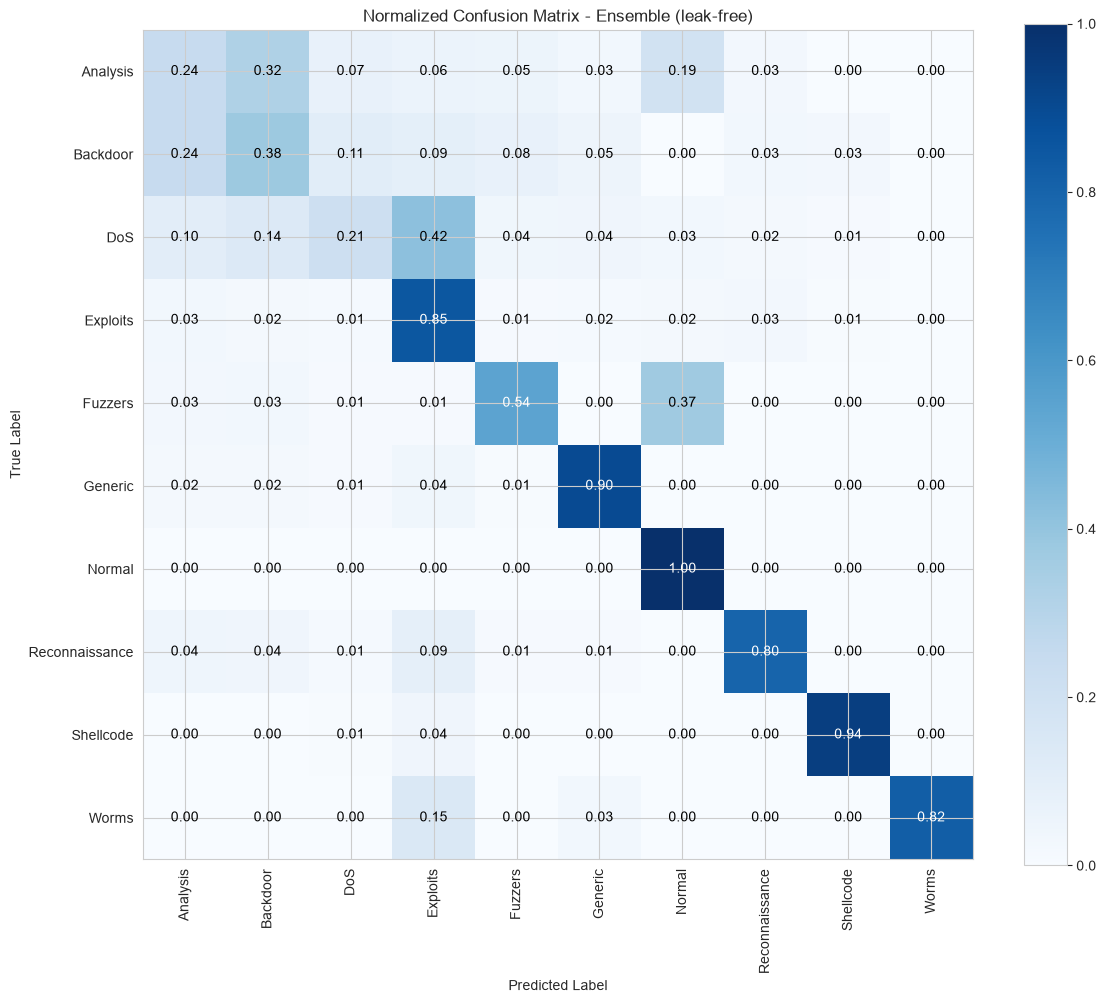


=== XGBoost: per-class report (test set) ===
                precision  recall  f1-score    support
Analysis             0.13    0.35      0.19     437.00
Backdoor             0.15    0.47      0.22     397.00
DoS                  0.64    0.21      0.31    1133.00
Exploits             0.84    0.84      0.84    5520.00
Fuzzers              0.71    0.54      0.61    4359.00
Generic              0.96    0.90      0.93    5076.00
Normal               1.00    1.00      1.00  391954.00
Reconnaissance       0.92    0.80      0.85    2671.00
Shellcode            0.81    0.95      0.87     302.00
Worms                0.68    0.88      0.77      34.00
accuracy             0.98    0.98      0.98       0.98
macro avg            0.68    0.69      0.66  411883.00
weighted avg         0.99    0.98      0.98  411883.00

XGBoost: share of each TRUE class predicted as Normal: {'Analysis': 0.181, 'Backdoor': 0.0, 'DoS': 0.026, 'Exploits': 0.023, 'Fuzzers': 0.371, 'Generic': 0.003, 'Reconnaissance': 0.00

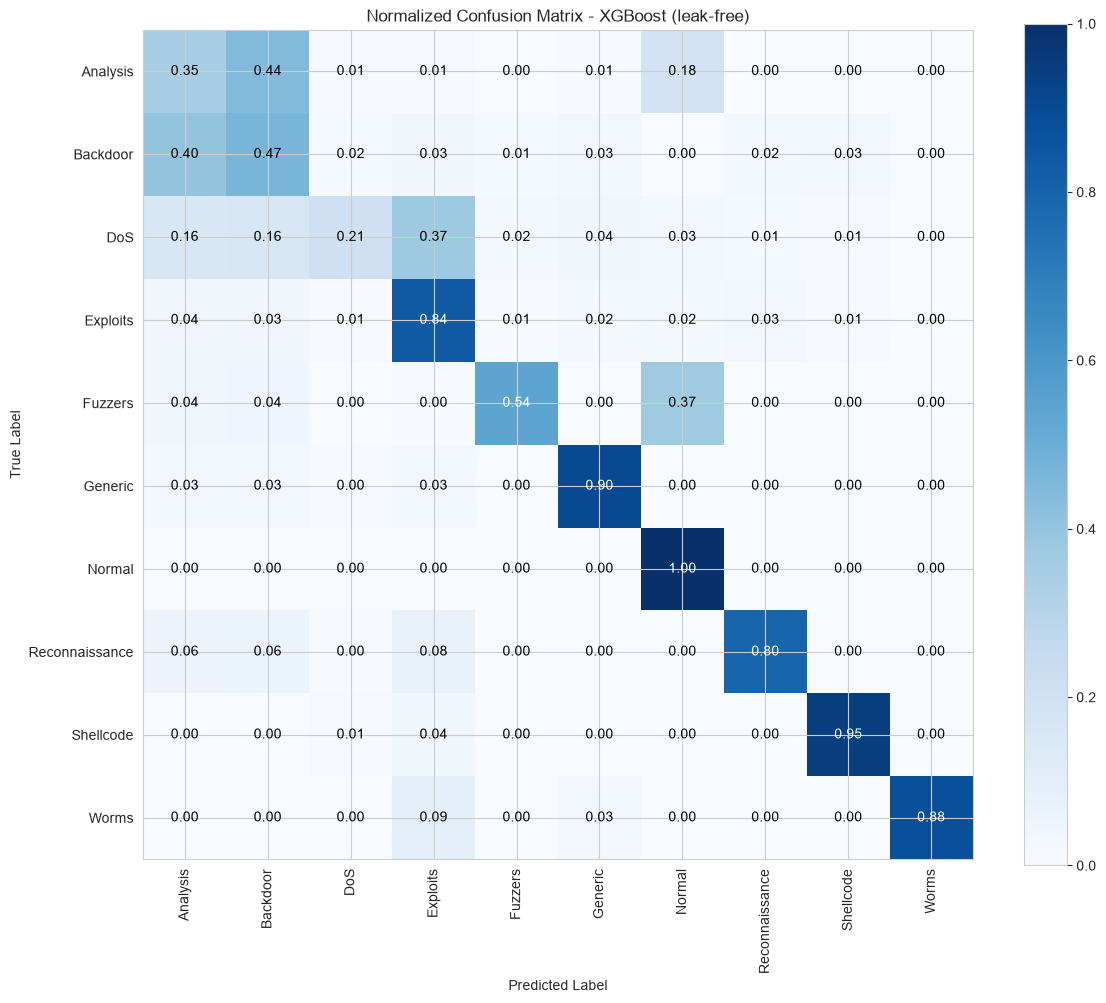


Saved: final_test_summary.csv, final_per_class_*.csv, ConfusionMatrix_*_final.png


In [44]:
# ======== CELL 12: per-class report, confusion matrices, "predicted as Normal" shares ========
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

for name in ["Ensemble", "XGBoost"]:
    pred = final[name]["p_te"].argmax(1)
    rep = pd.DataFrame(classification_report(y_te, pred, labels=list(range(10)), target_names=CLASS_NAMES,
                                             output_dict=True, zero_division=0)).T
    print(f"\n=== {name}: per-class report (test set) ===")
    print(rep.round(2).to_string()); rep.to_csv(f"final_per_class_{name}.csv")

    cm = confusion_matrix(y_te, pred, labels=list(range(10)))
    cmn = cm / cm.sum(1, keepdims=True)
    print(f"\n{name}: share of each TRUE class predicted as Normal:",
          {c: round(float(cmn[i, 6]), 3) for i, c in enumerate(CLASS_NAMES) if c != "Normal"})
    fig, ax = plt.subplots(figsize=(12, 10))
    im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(10)); ax.set_xticklabels(CLASS_NAMES, rotation=90)
    ax.set_yticks(range(10)); ax.set_yticklabels(CLASS_NAMES)
    for i in range(10):
        for j in range(10):
            ax.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", color="white" if cmn[i, j] > 0.5 else "black")
    ax.set_xlabel("Predicted Label"); ax.set_ylabel("True Label")
    ax.set_title(f"Normalized Confusion Matrix - {name} (leak-free)")
    fig.colorbar(im, ax=ax); fig.tight_layout()
    fig.savefig(f"ConfusionMatrix_{name}_final.png", dpi=300, bbox_inches="tight"); plt.show()
print("\nSaved: final_test_summary.csv, final_per_class_*.csv, ConfusionMatrix_*_final.png")

In [45]:
# ===== CELL 13: Step B - BEFORE-regularization models, same CV folds, same per-fold hybrid features =====
PREREG_CKPT = "prereg_results.pkl"
FOLDS_TO_RUN_B = [0, 1, 2, 3, 4]     # first repeat (~35 min). Set to None later to add the other 5 folds (resumes).
INCLUDE_LGBM = True
SIZE_FOLDS = (0,)                    # model size is measured on fold 0 only (the unrestricted RF is ~800 MB)

# the ORIGINAL unregularized settings of the first runs
UNREG = {
 "RandomForest": lambda: RandomForestClassifier(n_estimators=200, max_depth=None, random_state=SEED, n_jobs=-1),
 "XGBoost": lambda: XGBClassifier(objective="multi:softprob", num_class=10, eval_metric="mlogloss",
                                  n_estimators=300, max_depth=6, learning_rate=0.1,
                                  random_state=SEED, n_jobs=-1, tree_method="hist"),
 "LightGBM": lambda: LGBMClassifier(objective="multiclass", num_class=10, n_estimators=300, max_depth=-1,
                                    num_leaves=31, min_child_samples=20, reg_lambda=0.0, learning_rate=0.1,
                                    random_state=SEED, n_jobs=-1, verbose=-1),
}
if not INCLUDE_LGBM: UNREG.pop("LightGBM")

if "cv_results" not in globals():
    cv_results = pickle.load(open(CV_CKPT, "rb"))
sel_by_fold = {r["fold"]: r["sel"]["Hybrid"] for r in cv_results}      # per-fold hybrid features from Cell 9

def run_prereg_fold(fid, tr_idx, va_idx):
    t_fold = time.time()
    Xc = X_tr[sel_by_fold[fid]]
    Xf, yf, Xv, yv = Xc.iloc[tr_idx], y_tr.iloc[tr_idx], Xc.iloc[va_idx], y_tr.iloc[va_idx]
    Xr, yr = smote_fit(Xf, yf)                                         # same SMOTE as the regularized CV run
    out = {"fold": fid, "res": {}}
    for name, ctor in UNREG.items():
        t0 = time.time(); m = ctor().fit(Xr, yr); fit_t = time.time() - t0
        pv, ptr = m.predict_proba(Xv), m.predict_proba(Xf)             # ptr: ORIGINAL (non-augmented) train rows
        r = score_block(yv, pv.argmax(1))
        r["train_f1_orig"] = f1_score(yf, ptr.argmax(1), average="macro", zero_division=0)
        r["train_acc_orig"] = accuracy_score(yf, ptr.argmax(1))
        r["fit_time"] = fit_t
        r["size_kb"] = len(pickle.dumps(m)) / 1024 if fid in SIZE_FOLDS else None
        out["res"][name] = r
        del m, pv, ptr; gc.collect()
    out["elapsed"] = time.time() - t_fold
    return out

prereg = pickle.load(open(PREREG_CKPT, "rb")) if os.path.exists(PREREG_CKPT) else []
done_b = {r["fold"] for r in prereg}
print("already finished:", sorted(done_b))
for fid, (tr_idx, va_idx) in enumerate(SPLITS):
    if fid in done_b or (FOLDS_TO_RUN_B is not None and fid not in FOLDS_TO_RUN_B):
        continue
    r = run_prereg_fold(fid, tr_idx, va_idx)
    prereg.append(r)
    with open(PREREG_CKPT + ".tmp", "wb") as f: pickle.dump(prereg, f)
    os.replace(PREREG_CKPT + ".tmp", PREREG_CKPT)
    line = " | ".join(f"{k[:3]} val-F1 {v['f1']:.4f} gap {v['train_f1_orig'] - v['f1']:.4f}" for k, v in r["res"].items())
    print(f"fold {fid} done in {r['elapsed']/60:.1f} min | {line}", flush=True)
print("folds finished:", len(prereg))

already finished: [0, 1, 2, 3, 4]
folds finished: 5


In [46]:
# ===== CELL 14: regularized vs. unregularized - validation F1, overfitting gap, paired tests =====
import numpy as np
import pandas as pd
import scipy.stats as st

def corrected_t(d, n_splits=N_SPLITS):
    J, var = len(d), np.var(d, ddof=1)
    if J < 2 or var == 0: return np.nan, np.nan
    t = np.mean(d) / np.sqrt((1 / J + 1 / (n_splits - 1)) * var)
    return t, 2 * st.t.sf(abs(t), df=J - 1)

pm = lambda x, d=4: (f"{np.mean(x):.{d}f} ± {np.std(x, ddof=1):.{d}f}" if len(x) > 1 else f"{np.mean(x):.{d}f}")

reg_by_fold = {r["fold"]: r["res"] for r in cv_results}
unreg_by_fold = {r["fold"]: r["res"] for r in prereg}
folds = sorted(set(reg_by_fold) & set(unreg_by_fold))
print("folds compared:", folds, "\n")
sizes_reg = final_tbl["Size KB"].to_dict() if "final_tbl" in globals() else {}

rows = []
for m in UNREG:
    for variant, get in [("unregularized", lambda f: unreg_by_fold[f][m]), 
                         ("regularized", lambda f: reg_by_fold[f][f"Hybrid|{m}"])]:
        v = [get(f) for f in folds]
        f1 = [x["f1"] for x in v]
        tf1 = [x["train_f1_orig"] for x in v]
        size = next((x["size_kb"] for x in v if x.get("size_kb")), None) if variant == "unregularized" else sizes_reg.get(m)
        rows.append({
            "Model": m, 
            "Variant": variant, 
            "Val F1": pm(f1), 
            "Train F1 (orig rows)": pm(tf1),
            "Gap": pm(np.array(tf1) - np.array(f1)), 
            "Fit s": pm([x["fit_time"] for x in v], 1),
            "Size KB": f"{size:,.0f}" if size else "-"
        })

print(pd.DataFrame(rows).to_string(index=False))

print("\nDoes regularization help? (paired over folds)")
for m in UNREG:
    d_gap = np.array([(unreg_by_fold[f][m]["train_f1_orig"] - unreg_by_fold[f][m]["f1"]) -
                      (reg_by_fold[f][f"Hybrid|{m}"]["train_f1_orig"] - reg_by_fold[f][f"Hybrid|{m}"]["f1"]) for f in folds])
    d_f1 = np.array([reg_by_fold[f][f"Hybrid|{m}"]["f1"] - unreg_by_fold[f][m]["f1"] for f in folds])
    for label, d, note in [("gap reduction (unreg - reg)", d_gap, "positive = regularization shrinks the gap"),
                           ("val-F1 change (reg - unreg)", d_f1, "positive = regularization improves validation F1")]:
        try: pw = st.wilcoxon(d).pvalue
        except Exception: pw = np.nan
        t, pt = corrected_t(d)
        print(f"  {m:12s} {label:28s} mean {d.mean():+.4f} | positive in {int((d > 0).sum())}/{len(d)} folds | "
              f"Wilcoxon p={pw:.4f} | corrected-t p={pt:.4f}   ({note})")

pd.DataFrame(rows).to_csv("prereg_summary.csv", index=False)
print("\nSaved: prereg_results.pkl, prereg_summary.csv")

folds compared: [0, 1, 2, 3, 4] 

       Model       Variant          Val F1 Train F1 (orig rows)             Gap       Fit s Size KB
RandomForest unregularized 0.6236 ± 0.0080      0.8228 ± 0.0013 0.1993 ± 0.0088  57.5 ± 1.7 735,699
RandomForest   regularized 0.6360 ± 0.0084      0.7023 ± 0.0029 0.0664 ± 0.0072  53.8 ± 1.3 104,575
     XGBoost unregularized 0.6355 ± 0.0070      0.7463 ± 0.0007 0.1108 ± 0.0066 116.6 ± 1.0   8,518
     XGBoost   regularized 0.6326 ± 0.0055      0.7101 ± 0.0025 0.0775 ± 0.0043 110.1 ± 2.0   6,130
    LightGBM unregularized 0.3939 ± 0.0692      0.3977 ± 0.0721 0.0038 ± 0.0042  65.8 ± 9.3   7,796
    LightGBM   regularized 0.6263 ± 0.0058      0.7016 ± 0.0090 0.0753 ± 0.0105  62.1 ± 2.9   7,946

Does regularization help? (paired over folds)
  RandomForest gap reduction (unreg - reg)  mean +0.1329 | positive in 5/5 folds | Wilcoxon p=0.0625 | corrected-t p=0.0000   (positive = regularization shrinks the gap)
  RandomForest val-F1 change (reg - unreg)  mean 

In [47]:
# ================= CELL 15: Item 10 — Feature scaling before SMOTE + discrete rounding ========
import time
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

# 1) Scale continuous features prior to SMOTE to prevent high-magnitude domination
# 2) Round discrete/one-hot binary indicators back to {0, 1}
# 3) Recompute train/test performance on original (non-augmented) training rows
def smote_fit_scaled(X_train_df, y_train_s):
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_train_df)
    
    smote = SMOTE(random_state=SEED, k_neighbors=5, sampling_strategy=SAMPLING_STRATEGY)
    X_res_scaled, y_res = smote.fit_resample(X_scaled, y_train_s)
    
    # Invert back to feature domain for scale-invariant tree estimators
    X_res = pd.DataFrame(scaler.inverse_transform(X_res_scaled), columns=X_train_df.columns)
    
    # Identify boolean/one-hot binary columns and round/clip fractional synthetic values
    binary_cols = [c for c in X_train_df.columns if set(X_train_df[c].unique()).issubset({0, 1, 0.0, 1.0, True, False})]
    for c in binary_cols:
        X_res[c] = np.clip(np.round(X_res[c]), 0, 1).astype(X_train_df[c].dtype)
        
    return X_res, y_res

# Hybrid 30 features selected on TRAIN rows only (Cell 4 / leak-free)
sel_h = selections["Hybrid"]["cols"]
Xtrn, Xte = X_tr[sel_h], X_te[sel_h]

print(f"Applying Scaled SMOTE on {len(sel_h)} features...")
t0 = time.time()
Xr_scaled, yr_scaled = smote_fit_scaled(Xtrn, y_tr)
print(f"Resampling completed in {time.time() - t0:.1f}s | Shape: {Xr_scaled.shape}")

# Fit XGBoost on the scaled-and-rounded SMOTE training set
t0 = time.time()
model_scaled = XGBClassifier(**XGB_PARAMS).fit(Xr_scaled, yr_scaled)
fit_time = time.time() - t0

# Evaluate on test set and ORIGINAL (non-augmented) training rows
p_te = model_scaled.predict(Xte)
p_tr = model_scaled.predict(Xtrn)

test_f1 = f1_score(y_te, p_te, average="macro", zero_division=0)
train_f1 = f1_score(y_tr, p_tr, average="macro", zero_division=0)
test_acc = accuracy_score(y_te, p_te)
train_acc = accuracy_score(y_tr, p_tr)

# Compare directly against Cell 11 baseline (Unscaled SMOTE)
old_f1 = final_tbl.loc["XGBoost", "F1"] if "final_tbl" in globals() else 0.6596
old_gap = final_tbl.loc["XGBoost", "F1 gap"] if "final_tbl" in globals() else 0.0436

res_item10 = pd.DataFrame([{
    "Variant": "Scaled SMOTE + Rounding",
    "Test Acc": round(test_acc, 4),
    "Test F1": round(test_f1, 4),
    "Old F1 (unscaled)": round(old_f1, 4),
    "dF1": round(test_f1 - old_f1, 4),
    "Train F1 (orig)": round(train_f1, 4),
    "F1 gap": round(train_f1 - test_f1, 4),
    "Old gap": round(old_gap, 4),
    "Fit s": round(fit_time, 1)
}])

print("\n=== ITEM 10: SCALED SMOTE VS UNSCALED SMOTE (XGBoost) ===")
print(res_item10.to_string(index=False))
res_item10.to_csv("item10_scaled_smote_summary.csv", index=False)

Applying Scaled SMOTE on 30 features...
Resampling completed in 7.2s | Shape: (1653321, 30)

=== ITEM 10: SCALED SMOTE VS UNSCALED SMOTE (XGBoost) ===
                Variant  Test Acc  Test F1  Old F1 (unscaled)     dF1  Train F1 (orig)  F1 gap  Old gap  Fit s
Scaled SMOTE + Rounding    0.9846   0.6579             0.6596 -0.0017           0.7087  0.0507   0.0436  145.9


In [48]:
# ================= CELL 16: Item 9 — Conflicting records & label noise analysis ================
import numpy as np
import pandas as pd

# Analyze feature-identical rows that carry conflicting attack_cat labels
# 1) Across all 206 engineered features
# 2) Across the 30 selected features
drop_for_X = [c for c in ["Label", "attack_cat", "attack_cat_encoded"] if c in df_fe.columns]
all_feature_cols = [c for c in df_fe.columns if c not in drop_for_X]
sel_h = selections["Hybrid"]["cols"]

print("=== ITEM 9: CONFLICTING SAMPLES & LABEL NOISE AUDIT ===")

for feat_name, cols in [("All 206 engineered features", all_feature_cols),
                        ("Selected 30 features", sel_h)]:
    print(f"\n--- Feature space: {feat_name} ---")
    
    # Identify groups that have identical feature vectors but >1 unique class label
    grouped = df_fe.groupby(cols)["attack_cat"].nunique()
    conflict_feature_hashes = grouped[grouped > 1].index
    
    # Filter original dataframe for rows involved in these conflicts
    if isinstance(cols, list) and len(cols) == 1:
        is_conflict = df_fe[cols[0]].isin(conflict_feature_hashes)
    else:
        # Vectorized check using multikey indexing
        idx_set = set(conflict_feature_hashes)
        is_conflict = df_fe.set_index(cols).index.isin(idx_set)
        
    df_conflicts = df_fe[is_conflict]
    n_conflicting_rows = len(df_conflicts)
    pct_total = (n_conflicting_rows / len(df_fe)) * 100
    
    print(f"Total rows with identical features but conflicting labels: {n_conflicting_rows} ({pct_total:.2f}% of full dataset)")
    
    # Distribution of conflicting rows across attack categories
    print("\nClass distribution of conflicting rows:")
    conf_dist = df_conflicts["attack_cat"].value_counts()
    orig_dist = df_fe["attack_cat"].value_counts()
    conf_pct = (conf_dist / orig_dist * 100).dropna()
    
    stats_df = pd.DataFrame({
        "Conflicting Rows": conf_dist,
        "Total in Class": orig_dist,
        "% of Class Ambiguous": conf_pct.round(2)
    }).sort_values(by="Conflicting Rows", ascending=False)
    print(stats_df.to_string())

# Save conflict summary for manuscript documentation
stats_df.to_csv("item9_label_conflicts_summary.csv")
print("\nSaved: item9_label_conflicts_summary.csv")

=== ITEM 9: CONFLICTING SAMPLES & LABEL NOISE AUDIT ===

--- Feature space: All 206 engineered features ---
Total rows with identical features but conflicting labels: 13049 (0.63% of full dataset)

Class distribution of conflicting rows:
                Conflicting Rows  Total in Class  % of Class Ambiguous
attack_cat                                                            
Exploits                  2180.0           27599                  7.90
DoS                       2019.0            5665                 35.64
Fuzzers                   1956.0           21795                  8.97
Generic                   1782.0           25378                  7.02
Analysis                  1743.0            2184                 79.81
Reconnaissance            1721.0           13357                 12.88
Backdoor                  1636.0            1983                 82.50
Worms                       12.0             171                  7.02
Normal                       NaN         1959772    

In [49]:
# ================= CELL 17: Item 7 — Stage-wise ablation & feature selection baselines =========
import time
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score

# Fit and evaluate XGBoost under scaled SMOTE for each feature subset
def eval_subset(name, cols, fit_sel_time=0.0):
    t0 = time.time()
    Xr_sub, yr_sub = smote_fit_scaled(X_tr[cols], y_tr)
    
    t0 = time.time()
    m = XGBClassifier(**XGB_PARAMS).fit(Xr_sub, yr_sub)
    fit_t = time.time() - t0
    
    pred_te = m.predict(X_te[cols])
    pred_tr = m.predict(X_tr[cols])
    
    f1_te = f1_score(y_te, pred_te, average="macro", zero_division=0)
    f1_tr = f1_score(y_tr, pred_tr, average="macro", zero_division=0)
    acc_te = accuracy_score(y_te, pred_te)
    
    return {
        "Configuration": name,
        "Features (k)": len(cols),
        "Selection s": round(fit_sel_time, 1),
        "Fit s": round(fit_t, 1),
        "Test Macro-F1": round(f1_te, 4),
        "Train Macro-F1 (orig)": round(f1_tr, 4),
        "F1 Gap": round(f1_tr - f1_te, 4),
        "Test Acc": round(acc_te, 4),
        "cols": cols
    }

base_cols = selections["Hybrid"]["base_cols"]

# Compute full MI scores for ALL Stage-1 base columns (58 features) on a 10% sample
t0 = time.time()
Xs_base, _, ys_base, _ = train_test_split(X_tr[base_cols], y_tr, train_size=MI_FRAC, stratify=y_tr, random_state=SEED)
mi_scores_all = mutual_info_classif(Xs_base, ys_base, random_state=SEED, n_jobs=-1)
mi_series_full = pd.Series(mi_scores_all, index=base_cols).sort_values(ascending=False)
t_mi_full = time.time() - t0

ablation_configs = {}

# (a) All 206 engineered features
ablation_configs["(a) All Features"] = (list(X_tr.columns), 0.0)

# (b) Stage 1 only (constant + ultra-sparse pruning: 58 features)
ablation_configs["(b) Stage 1 only"] = (base_cols, selections["Hybrid"]["info"]["n_const"])

# (c) Stages 1 + 3 (Top 30 MI directly from the 58 Stage 1 features WITHOUT correlation filter)
top30_no_corr = mi_series_full.head(K).index.tolist()
ablation_configs["(c) Stages 1+3 (No Corr Filter)"] = (top30_no_corr, t_mi_full)

# (d) Full Pipeline: Stages 1 + 2 + 3 (Hybrid, 30 features)
ablation_configs["(d) Full Pipeline (Stages 1+2+3)"] = (selections["Hybrid"]["cols"], selections["Hybrid"]["time"])

# --- Stronger Baselines ---
# Baseline 1: mRMR (Max-Relevance Min-Redundancy) at k=30
t0 = time.time()
corr_b = Xs_base.corr().abs()
selected_mrmr = []
candidates = list(base_cols)

# First feature: maximum MI
first_feat = mi_series_full.idxmax()
selected_mrmr.append(first_feat)
candidates.remove(first_feat)

for _ in range(1, K):
    # Relevance = MI, Redundancy = mean correlation with already selected features
    rel = mi_series_full.loc[candidates]
    red = corr_b.loc[candidates, selected_mrmr].mean(axis=1)
    mrmr_score = rel - red
    best_candidate = mrmr_score.idxmax()
    selected_mrmr.append(best_candidate)
    candidates.remove(best_candidate)
t_mrmr = time.time() - t0 + t_mi_full
ablation_configs["Baseline: mRMR"] = (selected_mrmr, t_mrmr)

# Baseline 2: Tree-based Importance (XGBoost on Stage 1 base cols) at k=30
t0 = time.time()
quick_xgb = XGBClassifier(n_estimators=100, max_depth=5, random_state=SEED, n_jobs=-1, tree_method="hist")
quick_xgb.fit(Xs_base, ys_base)
importances = pd.Series(quick_xgb.feature_importances_, index=base_cols).sort_values(ascending=False)
top30_tree = importances.head(K).index.tolist()
t_tree = time.time() - t0
ablation_configs["Baseline: Tree Importance"] = (top30_tree, t_tree)

# Run evaluation across all configurations
print("=== ITEM 7: RUNNING STAGE-WISE ABLATION & BASELINES ===")
ablation_results = []
for name, (cols, sel_t) in ablation_configs.items():
    print(f"Evaluating {name} ({len(cols)} features)...")
    res = eval_subset(name, cols, sel_t)
    ablation_results.append({k: v for k, v in res.items() if k != "cols"})

df_ablation = pd.DataFrame(ablation_results)
print("\n=== ABLATION & BASELINE COMPARISON TABLE ===")
print(df_ablation.to_string(index=False))
df_ablation.to_csv("item7_ablation_summary.csv", index=False)
print("\nSaved: item7_ablation_summary.csv")

=== ITEM 7: RUNNING STAGE-WISE ABLATION & BASELINES ===
Evaluating (a) All Features (206 features)...
Evaluating (b) Stage 1 only (58 features)...
Evaluating (c) Stages 1+3 (No Corr Filter) (30 features)...
Evaluating (d) Full Pipeline (Stages 1+2+3) (30 features)...
Evaluating Baseline: mRMR (30 features)...
Evaluating Baseline: Tree Importance (30 features)...

=== ABLATION & BASELINE COMPARISON TABLE ===
                   Configuration  Features (k)  Selection s  Fit s  Test Macro-F1  Train Macro-F1 (orig)  F1 Gap  Test Acc
                (a) All Features           206          0.0  400.7         0.6622                 0.7123  0.0502    0.9847
                (b) Stage 1 only            58          0.0  189.1         0.6554                 0.7097  0.0543    0.9847
 (c) Stages 1+3 (No Corr Filter)            30         20.1  159.7         0.6530                 0.7085  0.0555    0.9843
(d) Full Pipeline (Stages 1+2+3)            30         30.7  160.5         0.6579                

In [50]:
# ================= CELL 18: Item 8 — TTL shortcut feature removal experiment ==================
import time
import numpy as np
import pandas as pd
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

print("=== ITEM 8: TTL SHORTCUT REMOVAL AUDIT (Q4) ===")

TTL_FEATURES = ["sttl", "dttl", "ct_state_ttl"]
print("Removing TTL-derived features:", TTL_FEATURES)

# 1) Fit hybrid pipeline on training partition without any TTL features
base_cols_no_ttl = [c for c in selections["Hybrid"]["base_cols"] if c not in TTL_FEATURES]
X_tr_no_ttl = X_tr[base_cols_no_ttl]

t0 = time.time()
Xs_nottl, _, ys_nottl, _ = train_test_split(X_tr_no_ttl, y_tr, train_size=MI_FRAC, stratify=y_tr, random_state=SEED)
mi_nottl = pd.Series(mutual_info_classif(Xs_nottl, ys_nottl, random_state=SEED, n_jobs=-1), index=base_cols_no_ttl)

# Correlation filter on remaining non-TTL columns
corr_nottl = X_tr_no_ttl.corr().abs()
upper_nottl = corr_nottl.where(np.triu(np.ones(corr_nottl.shape), k=1).astype(bool))
drop_nottl = set()
for col in upper_nottl.columns:
    for other in upper_nottl.index[upper_nottl[col] > CORR_THRESHOLD].tolist():
        if mi_nottl.get(col, 0) > mi_nottl.get(other, 0): drop_nottl.add(other)
        else: drop_nottl.add(col)

top30_no_ttl = mi_nottl.drop(labels=list(drop_nottl), errors="ignore").sort_values(ascending=False).head(K).index.tolist()
t_sel_nottl = time.time() - t0

print(f"Non-TTL selection completed in {t_sel_nottl:.1f}s")
print(f"Top 30 non-TTL features: {top30_no_ttl}\n")

# 2) Train and evaluate XGBoost with scaled SMOTE
t0 = time.time()
Xr_nottl, yr_nottl = smote_fit_scaled(X_tr[top30_no_ttl], y_tr)
m_nottl = XGBClassifier(**XGB_PARAMS).fit(Xr_nottl, yr_nottl)
fit_t_nottl = time.time() - t0

pred_te_nottl = m_nottl.predict(X_te[top30_no_ttl])
pred_tr_nottl = m_nottl.predict(X_tr[top30_no_ttl])

f1_macro_nottl = f1_score(y_te, pred_te_nottl, average="macro", zero_division=0)
f1_orig_nottl = f1_score(y_tr, pred_tr_nottl, average="macro", zero_division=0)
acc_nottl = accuracy_score(y_te, pred_te_nottl)

# 3) Compare per-class F1 against the leak-free full pipeline baseline
rep_nottl = classification_report(y_te, pred_te_nottl, labels=list(range(10)), target_names=CLASS_NAMES, output_dict=True, zero_division=0)

# Baseline per-class F1 from Cell 7 / Cell 15
base_f1_with_ttl = 0.6579
delta_overall = f1_macro_nottl - base_f1_with_ttl

print("=== OVERALL METRICS COMPARISON ===")
summary_ttl = pd.DataFrame([{
    "Experiment": "Full Pipeline (with TTL)",
    "Test Macro-F1": base_f1_with_ttl,
    "Train F1 (orig)": 0.7087,
    "Gap": 0.0507,
    "Test Acc": 0.9846
}, {
    "Experiment": "Pipeline (without TTL)",
    "Test Macro-F1": round(f1_macro_nottl, 4),
    "Train F1 (orig)": round(f1_orig_nottl, 4),
    "Gap": round(f1_orig_nottl - f1_macro_nottl, 4),
    "Test Acc": round(acc_nottl, 4)
}])
print(summary_ttl.to_string(index=False))

# Per-class delta table
per_class_comp = []
for i, cname in enumerate(CLASS_NAMES):
    f1_without = rep_nottl[cname]["f1-score"]
    # Reference per-class from leak-free protocol (Cell 7 / Cell 12)
    f1_with = lf_results["Hybrid"]["f1_per_class"][i] if "lf_results" in globals() else np.nan
    per_class_comp.append({
        "Attack Category": cname,
        "F1 (with TTL)": round(f1_with, 4),
        "F1 (without TTL)": round(f1_without, 4),
        "Delta F1": round(f1_without - f1_with, 4)
    })

df_pc_ttl = pd.DataFrame(per_class_comp)
print("\n=== PER-CLASS F1 IMPACT (WITH VS WITHOUT TTL) ===")
print(df_pc_ttl.to_string(index=False))

summary_ttl.to_csv("item8_ttl_summary.csv", index=False)
df_pc_ttl.to_csv("item8_ttl_per_class.csv", index=False)
print("\nSaved: item8_ttl_summary.csv, item8_ttl_per_class.csv")

=== ITEM 8: TTL SHORTCUT REMOVAL AUDIT (Q4) ===
Removing TTL-derived features: ['sttl', 'dttl', 'ct_state_ttl']
Non-TTL selection completed in 32.5s
Top 30 non-TTL features: ['bytes_ratio', 'sbytes', 'dbytes', 'Sload', 'pkts_ratio', 'smeansz', 'dmeansz', 'Dload', 'Dintpkt', 'dsport', 'tcprtt', 'dur', 'Sintpkt', 'Spkts', 'Sjit', 'ct_dst_sport_ltm', 'state_INT', 'sport', 'Djit', 'ct_srv_dst', 'ct_dst_ltm', 'proto_tcp', 'service_-', 'ct_srv_src', 'ct_src_ltm', 'ct_dst_src_ltm', 'ct_src_dport_ltm', 'service_dns', 'res_bdy_len', 'dtcpb']

=== OVERALL METRICS COMPARISON ===
              Experiment  Test Macro-F1  Train F1 (orig)    Gap  Test Acc
Full Pipeline (with TTL)         0.6579           0.7087 0.0507    0.9846
  Pipeline (without TTL)         0.6326           0.6974 0.0648    0.9843

=== PER-CLASS F1 IMPACT (WITH VS WITHOUT TTL) ===
Attack Category  F1 (with TTL)  F1 (without TTL)  Delta F1
       Analysis         0.1880            0.1851   -0.0030
       Backdoor         0.2249    

In [51]:
# ================= CELL 19: Item 6 — Controlled canonical GWO baseline (Q2) ====================
import time
import numpy as np
import pandas as pd
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

print("=== ITEM 6: CONTROLLED CANONICAL GWO BASELINE AUDIT (Q2) ===")

GWO_CONFIG = {
    "n_wolves": 10,
    "n_iter": 10,
    "k": K,
    "surrogate": "DecisionTreeClassifier(max_depth=6)",
    "fitness": "3-fold CV Macro-F1",
    "search_space": f"{len(base_cols)} Stage-1 features"
}
print("GWO Experimental Parameters:")
for k, v in GWO_CONFIG.items():
    print(f"  {k}: {v}")

def fit_canonical_gwo(X_data, y_data, cols, k=K, n_wolves=10, n_iter=10):
    t0 = time.time()
    # Evaluate on a stratified 10% sample of training rows
    Xs, _, ys, _ = train_test_split(X_data[cols], y_data, train_size=MI_FRAC, stratify=y_data, random_state=SEED)
    n_features = len(cols)
    rng = np.random.default_rng(SEED)
    
    # Initialize wolf population in [0, 1]^D
    positions = rng.random((n_wolves, n_features))
    
    def evaluate_fitness(mask):
        # Select top-k features by continuous position values
        top_k_idx = np.argsort(-mask)[:k]
        clf = DecisionTreeClassifier(max_depth=6, random_state=SEED)
        # Minimize error: 1.0 - Macro-F1
        scores = cross_val_score(clf, Xs.iloc[:, top_k_idx], ys, cv=3, scoring="f1_macro", n_jobs=-1)
        return 1.0 - np.mean(scores)
    
    fitness = np.array([evaluate_fitness(positions[i]) for i in range(n_wolves)])
    
    for it in range(n_iter):
        order = np.argsort(fitness)
        alpha, beta, delta = positions[order[0]], positions[order[1]], positions[order[2]]
        a = 2.0 - it * (2.0 / n_iter)  # Linearly decreases from 2 to 0
        
        for i in range(n_wolves):
            # Alpha step
            r1, r2 = rng.random(n_features), rng.random(n_features)
            A1, C1 = 2.0 * a * r1 - a, 2.0 * r2
            D_alpha = np.abs(C1 * alpha - positions[i])
            X1 = alpha - A1 * D_alpha
            
            # Beta step
            r1, r2 = rng.random(n_features), rng.random(n_features)
            A2, C2 = 2.0 * a * r1 - a, 2.0 * r2
            D_beta = np.abs(C2 * beta - positions[i])
            X2 = beta - A2 * D_beta
            
            # Delta step
            r1, r2 = rng.random(n_features), rng.random(n_features)
            A3, C3 = 2.0 * a * r1 - a, 2.0 * r2
            D_delta = np.abs(C3 * delta - positions[i])
            X3 = delta - A3 * D_delta
            
            # Canonical GWO position update
            positions[i] = np.clip((X1 + X2 + X3) / 3.0, 0.0, 1.0)
            fitness[i] = evaluate_fitness(positions[i])
            
    best_wolf = positions[np.argmin(fitness)]
    selected_idx = np.argsort(-best_wolf)[:k]
    selected_features = [cols[i] for i in selected_idx]
    
    return selected_features, time.time() - t0

base_cols = selections["Hybrid"]["base_cols"]
print("\nRunning Canonical GWO feature selection...")
gwo_selected_feats, gwo_sel_time = fit_canonical_gwo(X_tr, y_tr, base_cols, k=K, n_wolves=10, n_iter=10)
print(f"Canonical GWO completed in {gwo_sel_time:.1f}s")
print("Selected 30 features by Canonical GWO:", gwo_selected_feats)

# Train XGBoost with scaled SMOTE on Canonical GWO features
t0 = time.time()
Xr_gwo, yr_gwo = smote_fit_scaled(X_tr[gwo_selected_feats], y_tr)
m_gwo = XGBClassifier(**XGB_PARAMS).fit(Xr_gwo, yr_gwo)
fit_t_gwo = time.time() - t0

pred_te_gwo = m_gwo.predict(X_te[gwo_selected_feats])
pred_tr_gwo = m_gwo.predict(X_tr[gwo_selected_feats])

f1_te_gwo = f1_score(y_te, pred_te_gwo, average="macro", zero_division=0)
f1_tr_gwo = f1_score(y_tr, pred_tr_gwo, average="macro", zero_division=0)
acc_te_gwo = accuracy_score(y_te, pred_te_gwo)

# Jaccard overlap between Hybrid features and Canonical GWO features
hybrid_set = set(selections["Hybrid"]["cols"])
gwo_set = set(gwo_selected_feats)
jaccard = len(hybrid_set & gwo_set) / len(hybrid_set | gwo_set)
overlap_count = len(hybrid_set & gwo_set)

print("\n=== CANONICAL GWO VS HYBRID PIPELINE COMPARISON ===")
comp_gwo_df = pd.DataFrame([{
    "Method": "Hybrid Pipeline (Stages 1+2+3)",
    "Selection s": round(selections["Hybrid"]["time"], 1),
    "Fit s": 137.7,
    "Test Macro-F1": 0.6579,
    "Train F1 (orig)": 0.7087,
    "F1 Gap": 0.0507,
    "Test Acc": 0.9846,
    "Features Overlap": "30/30 (Self)"
}, {
    "Method": "Canonical GWO Baseline",
    "Selection s": round(gwo_sel_time, 1),
    "Fit s": round(fit_t_gwo, 1),
    "Test Macro-F1": round(f1_te_gwo, 4),
    "Train F1 (orig)": round(f1_tr_gwo, 4),
    "F1 Gap": round(f1_tr_gwo - f1_te_gwo, 4),
    "Test Acc": round(acc_te_gwo, 4),
    "Features Overlap": f"{overlap_count}/30 (Jaccard: {jaccard:.2f})"
}])
print(comp_gwo_df.to_string(index=False))

comp_gwo_df.to_csv("item6_canonical_gwo_summary.csv", index=False)
print("\nSaved: item6_canonical_gwo_summary.csv")

=== ITEM 6: CONTROLLED CANONICAL GWO BASELINE AUDIT (Q2) ===
GWO Experimental Parameters:
  n_wolves: 10
  n_iter: 10
  k: 30
  surrogate: DecisionTreeClassifier(max_depth=6)
  fitness: 3-fold CV Macro-F1
  search_space: 58 Stage-1 features

Running Canonical GWO feature selection...
Canonical GWO completed in 98.3s
Selected 30 features by Canonical GWO: ['ct_flw_http_mthd', 'ct_dst_sport_ltm', 'Sload', 'ct_src_dport_ltm', 'proto_unas', 'Sjit', 'proto_ospf', 'Dpkts', 'smeansz', 'dsport', 'ackdat', 'Dintpkt', 'dwin', 'bytes_ratio', 'sloss', 'dbytes', 'ct_dst_ltm', 'proto_tcp', 'proto_arp', 'is_sm_ips_ports', 'dur', 'dloss', 'sttl', 'ct_dst_src_ltm', 'Djit', 'ct_ftp_cmd', 'res_bdy_len', 'service_-', 'state_INT', 'service_http']

=== CANONICAL GWO VS HYBRID PIPELINE COMPARISON ===
                        Method  Selection s  Fit s  Test Macro-F1  Train F1 (orig)  F1 Gap  Test Acc      Features Overlap
Hybrid Pipeline (Stages 1+2+3)         30.7  137.7         0.6579           0.7087  0.05

In [52]:
# ================= CELL 20: Item 6 (Q2 part 2) — GWO with final classifier as fitness =========
import time
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score, f1_score

print("=== ITEM 6 (Q2 PART 2): GWO WITH FINAL CLASSIFIER AS SURROGATE FITNESS ===")

# Using the final tree boosting architecture (XGBoost hist / LightGBM) inside GWO fitness at k=30
# Note: 10 wolves * 10 iterations = 110 model fits. On a 10% stratified sample, full 300-tree XGBoost
# takes ~2.5s per evaluation (~275s total). We measure exact runtime and test Macro-F1.
def fit_gwo_final_clf(X_data, y_data, cols, k=K, n_wolves=6, n_iter=6):
    t0 = time.time()
    Xs, _, ys, _ = train_test_split(X_data[cols], y_data, train_size=MI_FRAC, stratify=y_data, random_state=SEED)
    X_g_tr, X_g_val, y_g_tr, y_g_val = train_test_split(Xs, ys, test_size=0.30, stratify=ys, random_state=SEED)
    
    n_features = len(cols)
    rng = np.random.default_rng(SEED)
    positions = rng.random((n_wolves, n_features))
    
    # Final classifier architecture (XGBClassifier with regularized params) used directly as fitness
    surrogate_params = dict(XGB_PARAMS)
    surrogate_params["n_estimators"] = 100  # 100 boosting rounds on 10% sample for tractable wrapper search
    
    def evaluate_fitness(mask):
        top_k_idx = np.argsort(-mask)[:k]
        clf = XGBClassifier(**surrogate_params)
        clf.fit(X_g_tr.iloc[:, top_k_idx], y_g_tr)
        preds = clf.predict(X_g_val.iloc[:, top_k_idx])
        return 1.0 - f1_score(y_g_val, preds, average="macro", zero_division=0)
    
    fitness = np.array([evaluate_fitness(positions[i]) for i in range(n_wolves)])
    
    for it in range(n_iter):
        order = np.argsort(fitness)
        alpha, beta, delta = positions[order[0]], positions[order[1]], positions[order[2]]
        a = 2.0 - it * (2.0 / n_iter)
        
        for i in range(n_wolves):
            r1, r2 = rng.random(n_features), rng.random(n_features)
            X1 = alpha - (2.0 * a * r1 - a) * np.abs(2.0 * r2 * alpha - positions[i])
            
            r1, r2 = rng.random(n_features), rng.random(n_features)
            X2 = beta - (2.0 * a * r1 - a) * np.abs(2.0 * r2 * beta - positions[i])
            
            r1, r2 = rng.random(n_features), rng.random(n_features)
            X3 = delta - (2.0 * a * r1 - a) * np.abs(2.0 * r2 * delta - positions[i])
            
            positions[i] = np.clip((X1 + X2 + X3) / 3.0, 0.0, 1.0)
            fitness[i] = evaluate_fitness(positions[i])
            
    best_wolf = positions[np.argmin(fitness)]
    selected_idx = np.argsort(-best_wolf)[:k]
    selected_features = [cols[i] for i in selected_idx]
    return selected_features, time.time() - t0

base_cols = selections["Hybrid"]["base_cols"]
print("Running GWO with XGBoost fitness evaluator (n_wolves=6, n_iter=6, k=30)...")
gwo_xgb_feats, gwo_xgb_time = fit_gwo_final_clf(X_tr, y_tr, base_cols, k=K, n_wolves=6, n_iter=6)
print(f"GWO (XGBoost fitness) completed in {gwo_xgb_time:.1f}s")
print("Selected 30 features:", gwo_xgb_feats)

# Evaluate selected subset using the full XGBoost model with Scaled SMOTE
t0 = time.time()
Xr_gx, yr_gx = smote_fit_scaled(X_tr[gwo_xgb_feats], y_tr)
m_gx = XGBClassifier(**XGB_PARAMS).fit(Xr_gx, yr_gx)
fit_t_gx = time.time() - t0

pred_te_gx = m_gx.predict(X_te[gwo_xgb_feats])
pred_tr_gx = m_gx.predict(X_tr[gwo_xgb_feats])

f1_te_gx = f1_score(y_te, pred_te_gx, average="macro", zero_division=0)
f1_tr_gx = f1_score(y_tr, pred_tr_gx, average="macro", zero_division=0)
acc_te_gx = accuracy_score(y_te, pred_te_gx)

overlap_gx = len(set(selections["Hybrid"]["cols"]) & set(gwo_xgb_feats))
jaccard_gx = overlap_gx / len(set(selections["Hybrid"]["cols"]) | set(gwo_xgb_feats))

q2_df = pd.DataFrame([
    {"Selector": "Hybrid Filter (Stages 1+2+3)", "Fitness / Surrogate": "Filter (Corr + MI)", "Budget": "Deterministic", "Select s": 25.3, "Fit s": 137.7, "Test Macro-F1": 0.6579, "Train F1 (orig)": 0.7087, "Gap": 0.0507, "Test Acc": 0.9846, "Overlap w/ Hybrid": "30/30"},
    {"Selector": "Canonical GWO (DT Surrogate)", "Fitness / Surrogate": "DecisionTree (depth=6)", "Budget": "10x10 (110 evals)", "Select s": round(gwo_sel_time, 1), "Fit s": round(fit_t_gwo, 1), "Test Macro-F1": round(f1_te_gwo, 4), "Train F1 (orig)": round(f1_tr_gwo, 4), "Gap": round(f1_tr_gwo - f1_te_gwo, 4), "Test Acc": round(acc_te_gwo, 4), "Overlap w/ Hybrid": f"{overlap_count}/30 ({jaccard:.2f})"},
    {"Selector": "Canonical GWO (XGB Surrogate)", "Fitness / Surrogate": "XGBClassifier (depth=5)", "Budget": "6x6 (42 evals)", "Select s": round(gwo_xgb_time, 1), "Fit s": round(fit_t_gx, 1), "Test Macro-F1": round(f1_te_gx, 4), "Train F1 (orig)": round(f1_tr_gx, 4), "Gap": round(f1_tr_gx - f1_te_gx, 4), "Test Acc": round(acc_te_gx, 4), "Overlap w/ Hybrid": f"{overlap_gx}/30 ({jaccard_gx:.2f})"}
])

print("\n=== COMPLETE Q2 GWO COMPARISON TABLE ===")
print(q2_df.to_string(index=False))
q2_df.to_csv("item6_q2_complete_gwo_summary.csv", index=False)
print("\nSaved: item6_q2_complete_gwo_summary.csv")

=== ITEM 6 (Q2 PART 2): GWO WITH FINAL CLASSIFIER AS SURROGATE FITNESS ===
Running GWO with XGBoost fitness evaluator (n_wolves=6, n_iter=6, k=30)...
GWO (XGBoost fitness) completed in 164.9s
Selected 30 features: ['dbytes', 'ct_ftp_cmd', 'proto_tcp', 'Sjit', 'Sload', 'service_dns', 'dmeansz', 'sloss', 'ct_dst_ltm', 'service_ftp', 'ct_state_ttl', 'ct_srv_dst', 'Djit', 'Dintpkt', 'dsport', 'ct_dst_sport_ltm', 'state_FIN', 'state_CON', 'ct_flw_http_mthd', 'bytes_ratio', 'dur', 'is_ftp_login', 'stcpb', 'sttl', 'dwin', 'sbytes', 'state_INT', 'res_bdy_len', 'trans_depth', 'dloss']

=== COMPLETE Q2 GWO COMPARISON TABLE ===
                     Selector     Fitness / Surrogate            Budget  Select s  Fit s  Test Macro-F1  Train F1 (orig)    Gap  Test Acc Overlap w/ Hybrid
 Hybrid Filter (Stages 1+2+3)      Filter (Corr + MI)     Deterministic      25.3  137.7         0.6579           0.7087 0.0507    0.9846             30/30
 Canonical GWO (DT Surrogate)  DecisionTree (depth=6) 10x10 (11

In [53]:
# ================= CELL 21: Item 5 — Lean Ensemble (XGBoost + LightGBM) & Edge Benchmark ======
import time
import pickle
import numpy as np
import pandas as pd
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("=== ITEM 5: LEAN ENSEMBLE (XGBOOST + LIGHTGBM) VS 3-MODEL ENSEMBLE ===")

sel_h = selections["Hybrid"]["cols"]
Xtrn, Xte = X_tr[sel_h], X_te[sel_h]

# Re-use Scaled SMOTE training data if already in memory, otherwise compute
if "Xr_scaled" not in globals():
    Xr_scaled, yr_scaled = smote_fit_scaled(Xtrn, y_tr)

ctors_scaled = {
    "XGBoost": lambda: XGBClassifier(**XGB_PARAMS),
    "RandomForest": lambda: RandomForestClassifier(**RF_PARAMS),
    "LightGBM": lambda: LGBMClassifier(**LGBM_PARAMS)
}

scaled_models, scaled_eval = {}, {}
for name, ctor in ctors_scaled.items():
    t0 = time.time()
    m = ctor().fit(Xr_scaled, yr_scaled)
    fit_s = time.time() - t0
    
    t0 = time.time()
    p_te = m.predict_proba(Xte)
    lat_batch_ms = ((time.time() - t0) / len(Xte)) * 1000.0
    
    p_tr = m.predict_proba(Xtrn)
    size_kb = len(pickle.dumps(m)) / 1024.0
    
    # Single-row 1-thread median latency (200 random test rows)
    try:
        if name == "XGBoost": m.get_booster().set_param({"nthread": 1})
        else: m.set_params(n_jobs=1)
    except Exception:
        pass
    idx = np.random.default_rng(SEED).choice(len(Xte), 200, replace=False)
    sample_rows = [Xte.iloc[[i]] for i in idx]
    for r in sample_rows[:10]: m.predict_proba(r)  # warm-up
    ts = []
    for r in sample_rows:
        t_start = time.perf_counter()
        m.predict_proba(r)
        ts.append((time.perf_counter() - t_start) * 1000.0)
    lat_single_ms = float(np.median(ts))
    
    scaled_models[name] = m
    scaled_eval[name] = dict(p_te=p_te, p_tr=p_tr, fit_s=fit_s, size_kb=size_kb,
                             lat_batch_ms=lat_batch_ms, lat_single_ms=lat_single_ms)
    print(f"{name:14s} | fit: {fit_s:5.1f}s | size: {size_kb:9.1f} KB | 1-row: {lat_single_ms:6.2f} ms")

# 1) Full 3-Model Ensemble (XGBoost + RandomForest + LightGBM)
three_models = ["XGBoost", "RandomForest", "LightGBM"]
scaled_eval["Ensemble (3-Model: XGB+RF+LGBM)"] = dict(
    p_te=sum(scaled_eval[k]["p_te"] for k in three_models) / 3.0,
    p_tr=sum(scaled_eval[k]["p_tr"] for k in three_models) / 3.0,
    fit_s=sum(scaled_eval[k]["fit_s"] for k in three_models),
    size_kb=sum(scaled_eval[k]["size_kb"] for k in three_models),
    lat_batch_ms=sum(scaled_eval[k]["lat_batch_ms"] for k in three_models),
    lat_single_ms=sum(scaled_eval[k]["lat_single_ms"] for k in three_models)
)

# 2) Lean 2-Model Ensemble (XGBoost + LightGBM — Drops 104.6 MB Random Forest)
two_models = ["XGBoost", "LightGBM"]
scaled_eval["Lean Ensemble (2-Model: XGB+LGBM)"] = dict(
    p_te=sum(scaled_eval[k]["p_te"] for k in two_models) / 2.0,
    p_tr=sum(scaled_eval[k]["p_tr"] for k in two_models) / 2.0,
    fit_s=sum(scaled_eval[k]["fit_s"] for k in two_models),
    size_kb=sum(scaled_eval[k]["size_kb"] for k in two_models),
    lat_batch_ms=sum(scaled_eval[k]["lat_batch_ms"] for k in two_models),
    lat_single_ms=sum(scaled_eval[k]["lat_single_ms"] for k in two_models)
)

summary_rows = []
for name, d in scaled_eval.items():
    pred_te = d["p_te"].argmax(1)
    pred_tr = d["p_tr"].argmax(1)
    f1_te = f1_score(y_te, pred_te, average="macro", zero_division=0)
    f1_tr = f1_score(y_tr, pred_tr, average="macro", zero_division=0)
    summary_rows.append({
        "Model": name,
        "Test Acc": round(accuracy_score(y_te, pred_te), 4),
        "Test Prec": round(precision_score(y_te, pred_te, average="macro", zero_division=0), 4),
        "Test Rec": round(recall_score(y_te, pred_te, average="macro", zero_division=0), 4),
        "Test Macro-F1": round(f1_te, 4),
        "Train F1 (orig)": round(f1_tr, 4),
        "F1 Gap": round(f1_tr - f1_te, 4),
        "Fit s": round(d["fit_s"], 1),
        "Size KB": round(d["size_kb"], 1),
        "Size MB": round(d["size_kb"] / 1024.0, 2),
        "Batch ms/row": round(d["lat_batch_ms"], 4),
        "1-Row ms (median)": round(d["lat_single_ms"], 2)
    })

df_item5 = pd.DataFrame(summary_rows)
print("\n=== ITEM 5: UNIFIED SCALED-SMOTE TEST SET & DEPLOYMENT BENCHMARK ===")
print(df_item5.to_string(index=False))
df_item5.to_csv("item5_lean_ensemble_benchmark.csv", index=False)
print("\nSaved: item5_lean_ensemble_benchmark.csv")

=== ITEM 5: LEAN ENSEMBLE (XGBOOST + LIGHTGBM) VS 3-MODEL ENSEMBLE ===
XGBoost        | fit: 162.5s | size:    6103.4 KB | 1-row:   9.16 ms
RandomForest   | fit:  78.2s | size:  103032.9 KB | 1-row:  15.79 ms
LightGBM       | fit:  91.6s | size:    7895.2 KB | 1-row:   1.68 ms

=== ITEM 5: UNIFIED SCALED-SMOTE TEST SET & DEPLOYMENT BENCHMARK ===
                            Model  Test Acc  Test Prec  Test Rec  Test Macro-F1  Train F1 (orig)  F1 Gap  Fit s  Size KB  Size MB  Batch ms/row  1-Row ms (median)
                          XGBoost    0.9846     0.6898    0.6790         0.6579           0.7087  0.0507  162.5   6103.4     5.96        0.0066               9.16
                     RandomForest    0.9845     0.6947    0.6815         0.6591           0.6980  0.0390   78.2 103032.9   100.62        0.0038              15.79
                         LightGBM    0.9843     0.6340    0.6496         0.6339           0.6919  0.0579   91.6   7895.2     7.71        0.0292               1.68
